# Bank Term Deposit Subscription: Prediction and Marketing Strategy (PRCP-1000, v2)

**Domain:** Finance / Banking | **Task:** Binary classification | **Target:** `subscribed` (1 = subscribed to a term deposit)

**Data:** `bank-additional-full.csv`, 41,188 records from direct phone campaigns of a Portuguese bank (May 2008 to November 2010), described in Moro, Cortez and Rita (2014) [1]. Records are in date order.

## Validation design (read this first)
The file covers one time-ordered history, so two protocols are used, each with a distinct purpose:

| Window | Records | Purpose | Used for |
|---|---|---|---|
| **Development window D** = first 80% of the file | 32,940 | Random protocol | 5-fold CV on D_train (80% of D) for tuning and selection; random 20% of D (D_test) for the final random-protocol test |
| **Chronological train** = first 60% | 24,705 | Chronological protocol | Feature selection and fitting |
| **Chronological validation** = next 20% | 8,235 | Chronological protocol | Hyperparameter tuning, model selection, threshold |
| **Chronological test** = last 20% | 8,236 | Final forward-in-time test | Touched **once**, after all decisions are fixed |

The random protocol estimates performance when training and test periods are similar. The chronological protocol estimates performance on a later, unseen period, which is what the bank will face. Both use the same candidate families and the same metrics, so they can be compared on the same final test set (Section 7).

**Run from a clean runtime:** Runtime → Run all. In Colab, select `bank-additional-full.csv` when prompted.

## 0. Setup and Data Loading

In [1]:
# Import NumPy and Pandas for data handling
import itertools
import numpy as np
import pandas as pd

# Import plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import scikit-learn tools for splitting, cross-validation and pipelines
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Import the classifiers that will be compared
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# Import metrics, calibration and permutation importance
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_recall_curve, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, accuracy_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

# Fix the random seeds so every result is reproducible
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# Number of bootstrap resamples used for uncertainty estimates
N_BOOT = 1000

# Use a clean plot style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

### Upload the dataset
In Colab, select `bank-additional-full.csv`. Elsewhere, the notebook reads a local file with that name.

In [2]:
# Try the Colab file picker; outside Colab, use the local file name
try:
    from google.colab import files
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
except ImportError:
    file_name = "bank-additional-full.csv"

# Load the data: this file uses semicolons as separators
df_raw = pd.read_csv(file_name, sep=";")
print("Loaded file:", file_name)

Loaded file: bank-additional-full.csv


## 1. Dataset Understanding and Validation

In [3]:
# Check the shape and column types
print("Shape (rows, columns):", df_raw.shape)
print(df_raw.dtypes.value_counts())
display(df_raw.head())

# Check for missing values (categories are coded as "unknown" and are checked separately)
print("Missing values (NaN):", int(df_raw.isna().sum().sum()))

# Confirm the target values
print("Target 'y' values:", sorted(df_raw["y"].unique()))

# Count exact duplicate rows
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))

Shape (rows, columns): (41188, 21)
str        11
int64       5
float64     5
Name: count, dtype: int64


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Missing values (NaN): 0
Target 'y' values: ['no', 'yes']
Exact duplicate rows: 12


In [4]:
# Show the duplicated rows before removing them
display(df_raw[df_raw.duplicated(keep=False)].head(6))

# Remove exact duplicates, keeping the first copy and the original (chronological) order
df = df_raw.drop_duplicates().reset_index(drop=True)
print("Rows before:", df_raw.shape[0], "| Rows after:", df.shape[0])

# Create the binary target and remove the original text column
df["subscribed"] = (df["y"] == "yes").astype(int)
df = df.drop(columns="y")

# Record the chronological position of each row (the file is in date order)
df["period_index"] = np.arange(len(df))
print("Subscription rate overall:", round(df["subscribed"].mean(), 4))

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no


Rows before: 41188 | Rows after: 41176
Subscription rate overall: 0.1127


In [5]:
# Define the pre-call feature engineering in one function, used for training AND prediction
def add_features(frame):
    out = frame.copy()
    # 999 in pdays means the client was never contacted in an earlier campaign
    out["previously_contacted"] = (out["pdays"] != 999).astype(int)
    # Replace the 999 sentinel with -1 so "never contacted" is not read as a large number of days
    out["pdays_clean"] = out["pdays"].where(out["pdays"] != 999, -1)
    # 'campaign' counts the current call; contacts already made before the call is campaign - 1
    if "campaign" in out.columns:
        out["contacts_before_call"] = out["campaign"] - 1
    # Candidate interaction: cellular contact to a client who was contacted before
    out["cellular_x_prev_contact"] = ((out["contact"] == "cellular") & (out["previously_contacted"] == 1)).astype(int)
    return out

df = add_features(df)

# Define the input groups
MACRO = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
NUM_CORE = ["age", "contacts_before_call", "previous"]
CAT = ["job", "marital", "education", "default", "housing", "loan",
       "contact", "month", "day_of_week", "poutcome"]

# Guard against leakage: call duration must never be a model input
assert "duration" not in NUM_CORE + MACRO + CAT
print("Core numerical inputs:", NUM_CORE)
print("Macroeconomic inputs:", MACRO)
print("Categorical inputs:", CAT)

Core numerical inputs: ['age', 'contacts_before_call', 'previous']
Macroeconomic inputs: ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical inputs: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


### 1.1 Pre-call availability audit
Each input is checked against the moment a call is placed (Section 1.1 of the report).

In [6]:
# Check the pre-call availability of every candidate input, with the reason for the decision
audit = pd.DataFrame([
    ["age, job, marital, education, default, housing, loan", "Client record", "Yes", "Known before the call"],
    ["contact, month, day_of_week", "Call plan", "Yes", "Channel and call date are chosen before dialling"],
    ["campaign (used as contacts_before_call = campaign - 1)", "Campaign history", "Yes", "Calls already made are known; the value counts the current call, so the input subtracts one"],
    ["pdays, previous, poutcome", "Earlier campaigns", "Yes", "Recorded before this campaign"],
    ["emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed", "National indicators", "Conditional", "Published with a lag (daily to quarterly); the value for the call date may not yet be published, so production must use the latest published values"],
    ["duration", "Call outcome", "No", "Length of the call, known only after it ends. Excluded from all models; used only in the labelled benchmark (Section 10)"],
], columns=["Input", "Source", "Available before the call?", "Reason"])
display(audit)

,Input,Source,Available before the call?,Reason
0,"age, job, marital, education, default, housing...",Client record,Yes,Known before the call
1,"contact, month, day_of_week",Call plan,Yes,Channel and call date are chosen before dialling
2,campaign (used as contacts_before_call = campa...,Campaign history,Yes,Calls already made are known; the value counts...
3,"pdays, previous, poutcome",Earlier campaigns,Yes,Recorded before this campaign
4,"emp.var.rate, cons.price.idx, cons.conf.idx, e...",National indicators,Conditional,Published with a lag (daily to quarterly); the...
5,duration,Call outcome,No,"Length of the call, known only after it ends. ..."


## 2. Exploratory Data Analysis
EDA is descriptive. It uses the full file to describe the campaign. No model choice is made from EDA; all modelling decisions are made later on training data only.

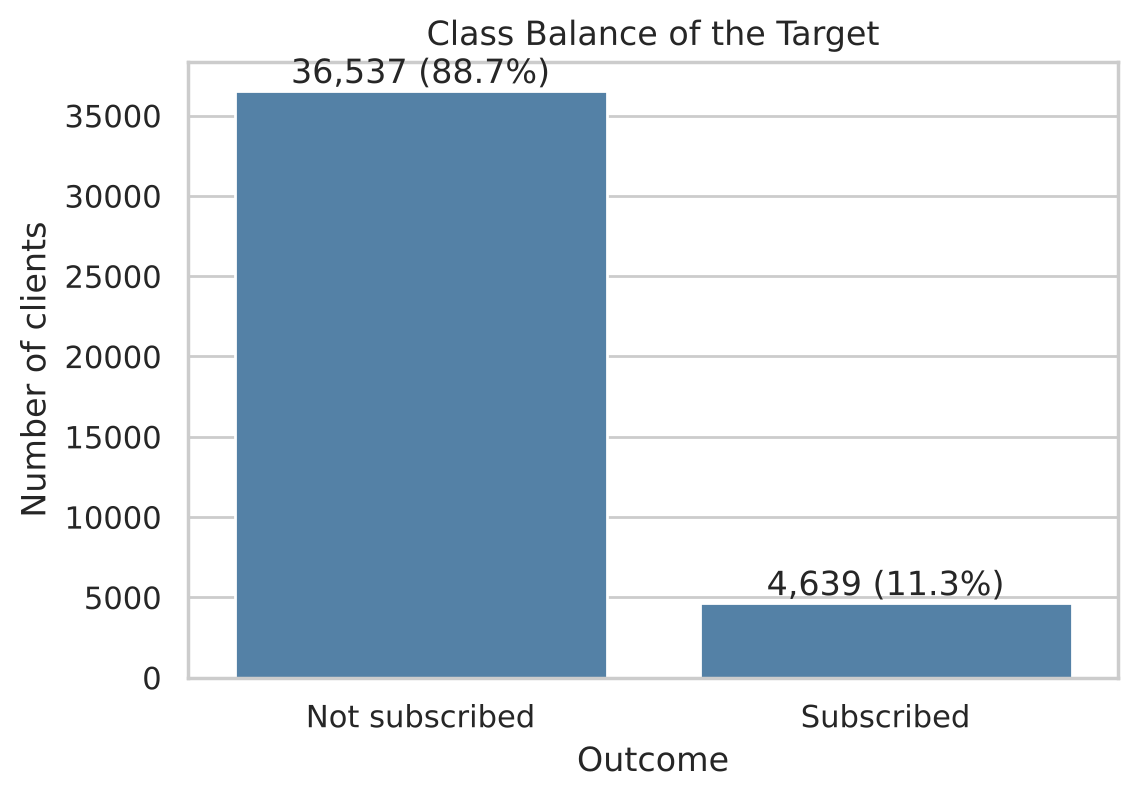

In [7]:
# Show the class balance of the target
counts = df["subscribed"].map({0: "Not subscribed", 1: "Subscribed"}).value_counts()
plt.figure(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, color="steelblue")
plt.title("Class Balance of the Target")
plt.xlabel("Outcome")
plt.ylabel("Number of clients")
for i, v in enumerate(counts.values):
    plt.text(i, v, f"{v:,} ({v / len(df):.1%})", ha="center", va="bottom")
plt.show()

**Observation.** 11.27% of the 41,176 unique records subscribed (4,639 clients), so about 89% did not. A model that predicts "no" for everyone would be 89% accurate, which is why this report uses ROC-AUC and PR-AUC. **Business relevance:** the call list will be mostly non-buyers, so value comes from ranking clients, not from headline accuracy.

,mean,median,std,min,max,skew,kurt
age,40.024,38.000,10.421,17.000,98.000,0.785,0.791
campaign,2.568,2.000,2.770,1.000,56.000,4.762,36.972
previous,0.173,0.000,0.495,0.000,7.000,3.831,20.102
emp.var.rate,0.082,1.100,1.571,-3.400,1.400,-0.724,-1.063
cons.price.idx,93.576,93.749,0.579,92.201,94.767,-0.231,-0.830
cons.conf.idx,-40.503,-41.800,4.628,-50.800,-26.900,0.303,-0.359
euribor3m,3.621,4.857,1.734,0.634,5.045,-0.709,-1.407
nr.employed,5167.035,5191.000,72.251,4963.600,5228.100,-1.044,-0.004


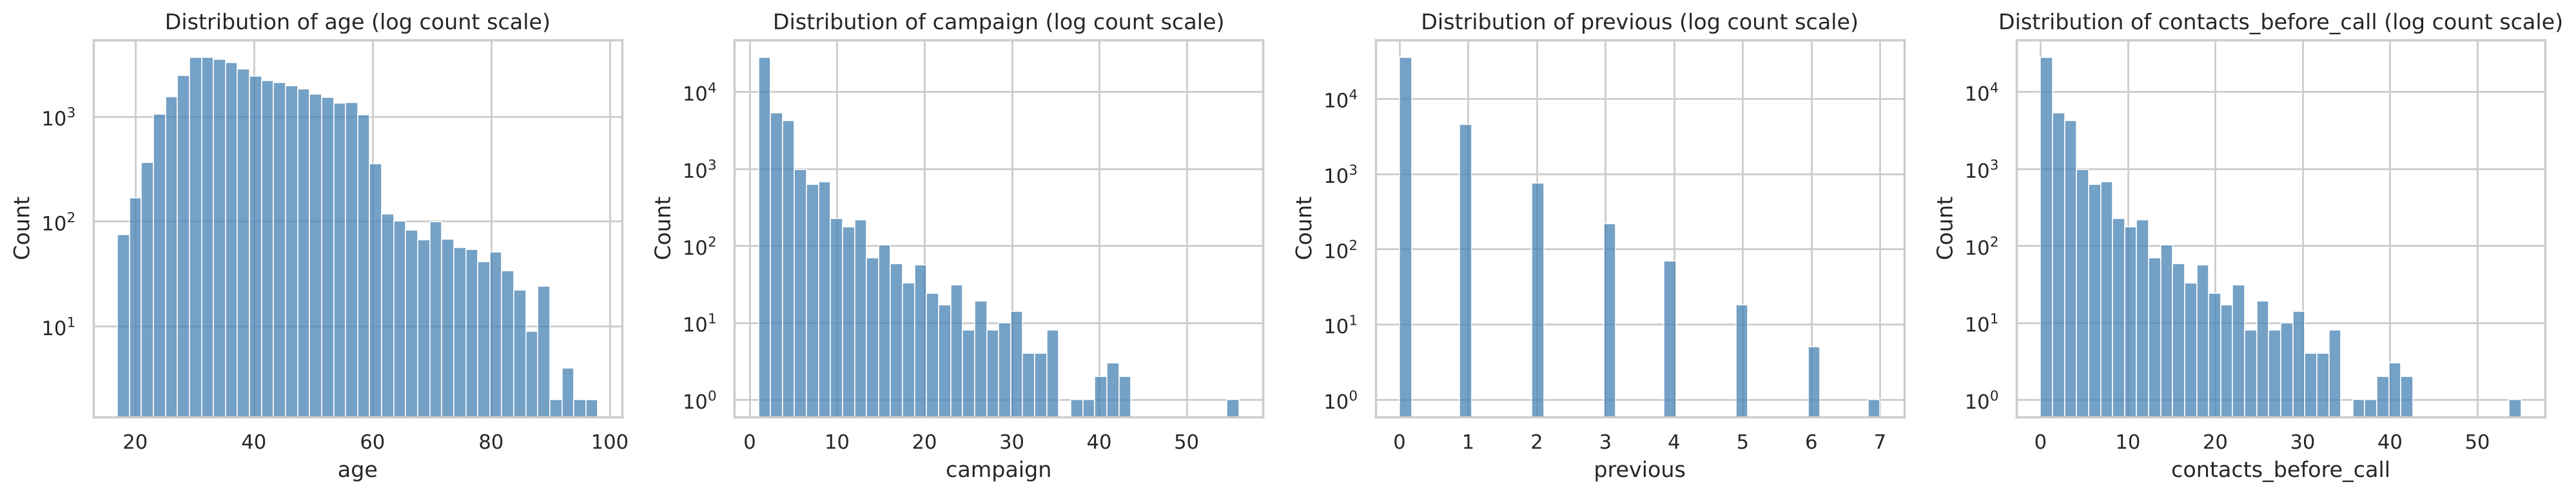

In [8]:
# Summarize the numerical distributions: centre, spread, skewness, tails
num_summary = df[["age", "campaign", "previous", "emp.var.rate", "cons.price.idx",
                  "cons.conf.idx", "euribor3m", "nr.employed"]].agg(["mean", "median", "std", "min", "max", "skew", "kurt"]).T.round(3)
display(num_summary)

# Show histograms of the three count-like and age variables, to see their shape
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ["age", "campaign", "previous", "contacts_before_call"]):
    sns.histplot(df[col], bins=40, ax=ax, color="steelblue")
    ax.set_yscale("log")
    ax.set_title(f"Distribution of {col} (log count scale)")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

**Observation.** Age is nearly symmetric (mean 40.0, median 38, skew 0.79). Campaign contacts are strongly right-skewed (skew 4.76, kurtosis 36.97, maximum 56), and so are previous contacts (skew 3.83, maximum 7). The macroeconomic indicators are left-skewed over this period (employment variation skew −0.72; number employed −1.04). **Outliers:** 468 clients are older than the age fence of 69.5 years, and 869 had 10 or more calls before this one. Both groups are valid records and are retained (see the outlier cell below). **Business relevance:** the long call-count tail matters for a call-limit policy (Section 13), not for model distortion, because inputs are standardized and tree models are robust to extreme values.

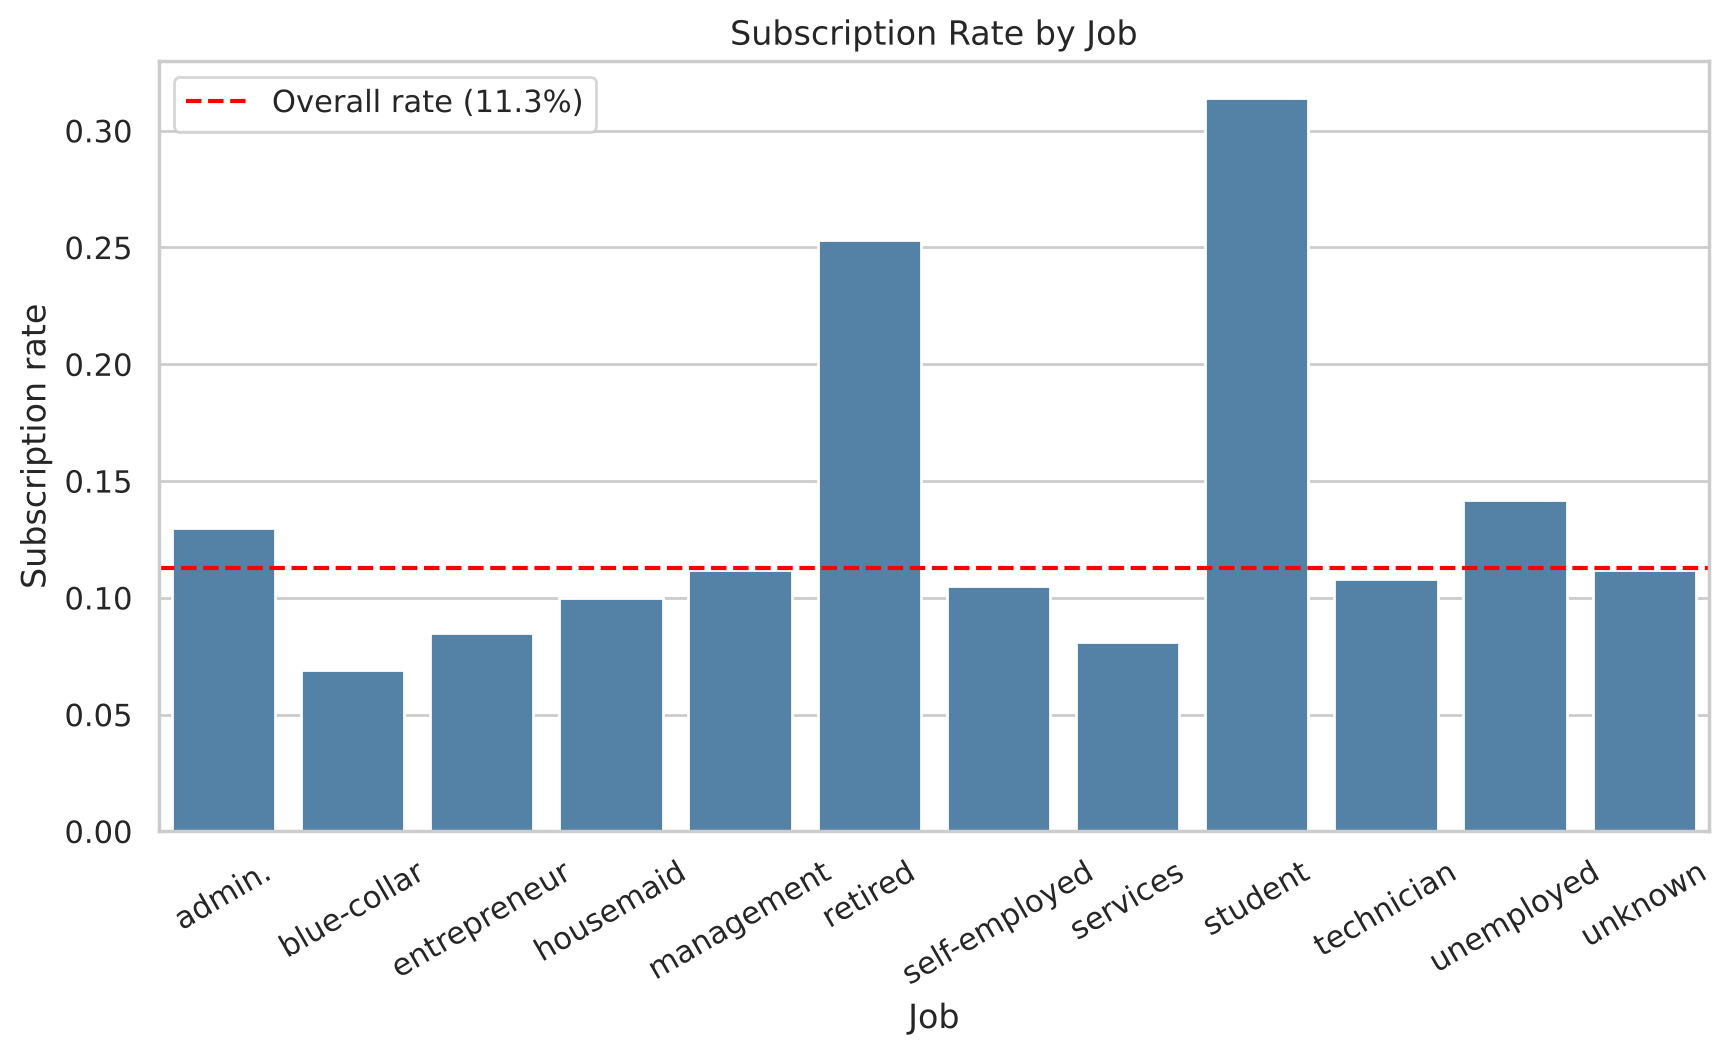

,records,subscribers,rate
job,,,
student,875,275,0.314
retired,1718,434,0.253
unemployed,1014,144,0.142
admin.,10419,1351,0.130
unknown,330,37,0.112
management,2924,328,0.112
technician,6739,730,0.108
self-employed,1421,149,0.105
housemaid,1060,106,0.100


In [9]:
# Summarize the subscription rate by job
def subscription_rate(column, order=None):
    table = df.groupby(column)["subscribed"].agg(records="size", subscribers="sum", rate="mean")
    if order is not None:
        table = table.reindex(order)
    table["rate"] = table["rate"].round(3)
    return table

def rate_bar(column, title, xlabel, order=None, rotate=0):
    table = subscription_rate(column, order)
    overall = df["subscribed"].mean()
    plt.figure(figsize=(10, 5))
    sns.barplot(x=table.index.astype(str), y=table["rate"].values, color="steelblue")
    plt.axhline(overall, color="red", linestyle="--", label=f"Overall rate ({overall:.1%})")
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Subscription rate")
    plt.xticks(rotation=rotate)
    plt.legend()
    plt.show()
    return table

job_table = rate_bar("job", "Subscription Rate by Job", "Job", rotate=30)
display(job_table.sort_values("rate", ascending=False))

**Observation.** Students subscribe at 31.4% (275 of 875) and retired clients at 25.3% (434 of 1,718), against 11.3% overall. Blue-collar clients are lowest at 6.9% (638 of 9,253), followed by services at 8.1%. Admin (13.0%, 10,419 records) is slightly above average. **Business relevance:** job is a strong segment signal. The student and retired groups are small, so their rates carry wider uncertainty.

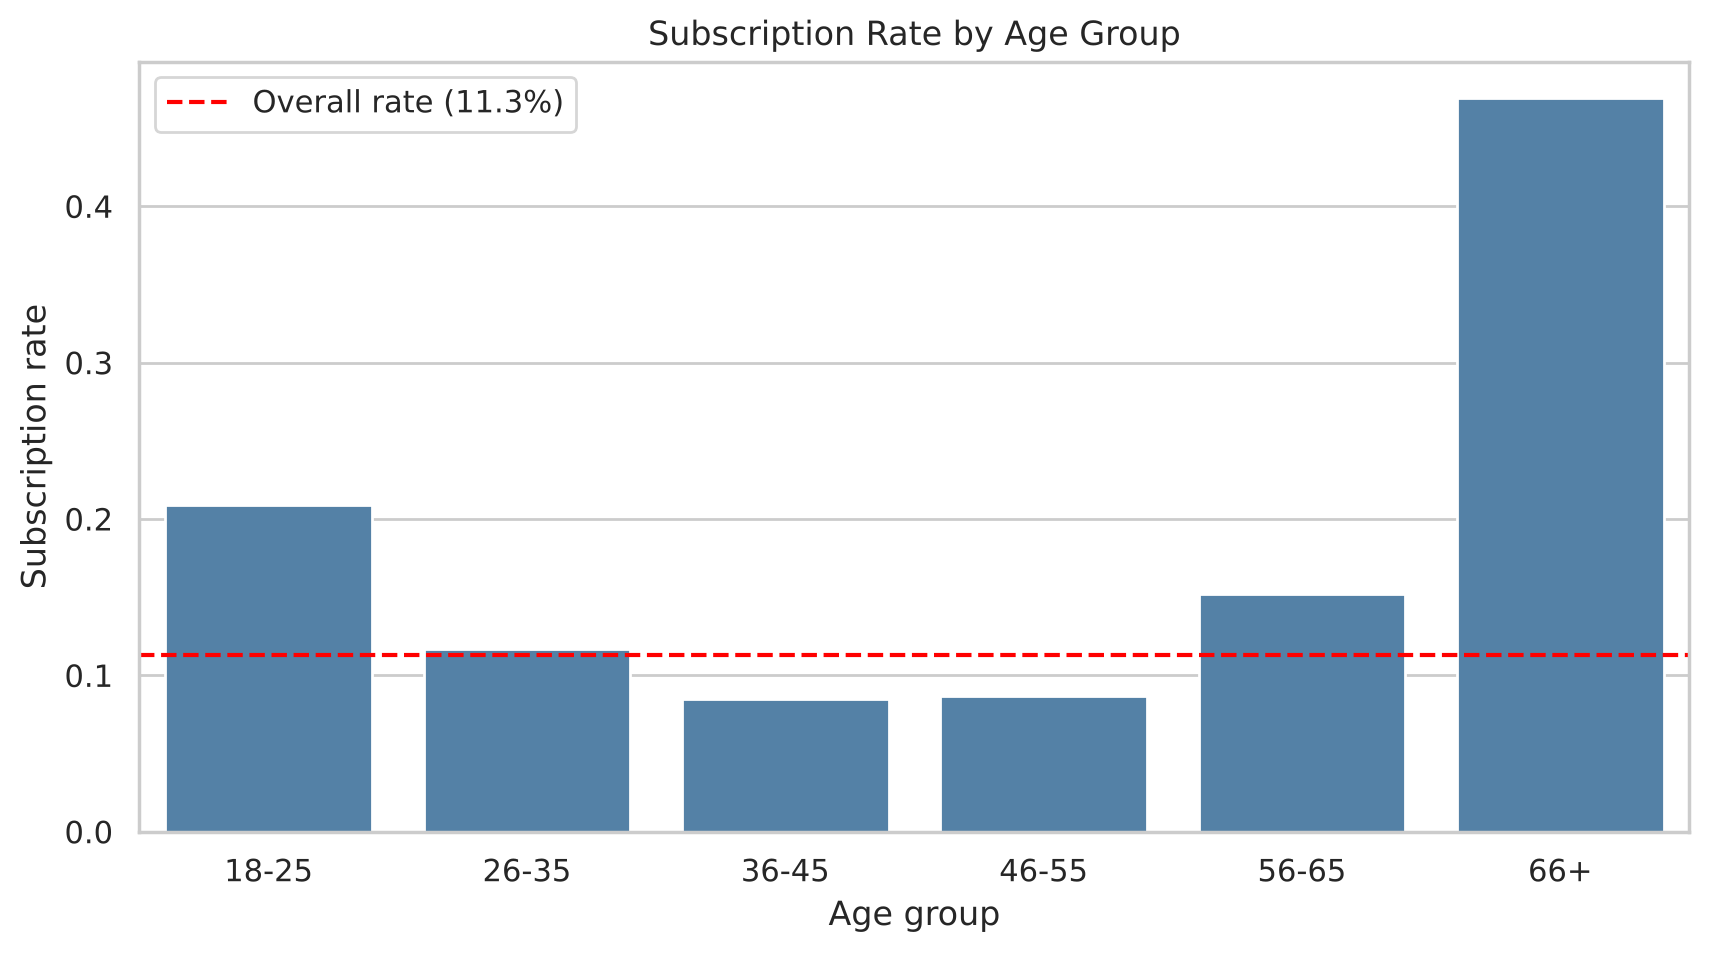

,records,subscribers,rate
age_group,,,
18-25,1660,347,0.209
26-35,14844,1740,0.117
36-45,12839,1092,0.085
46-55,8247,717,0.087
56-65,2963,451,0.152
66+,618,290,0.469


In [10]:
# Group ages into bands and show the subscription rate by age group
df["age_group"] = pd.cut(df["age"], bins=[17, 25, 35, 45, 55, 65, 100],
                         labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66+"])
age_table = rate_bar("age_group", "Subscription Rate by Age Group", "Age group")
display(age_table)

**Observation.** Rates are highest for clients aged 66 and over (46.9%, 290 of 618) and for ages 18–25 (20.9%, 347 of 1,660), and lowest for ages 36–45 (8.5%) and 46–55 (8.7%). Ages 56–65 sit at 15.2%. **Business relevance:** the middle-aged majority responds least, so older and younger segments may need different offers. The 66+ group is small, so its exact rate is uncertain.

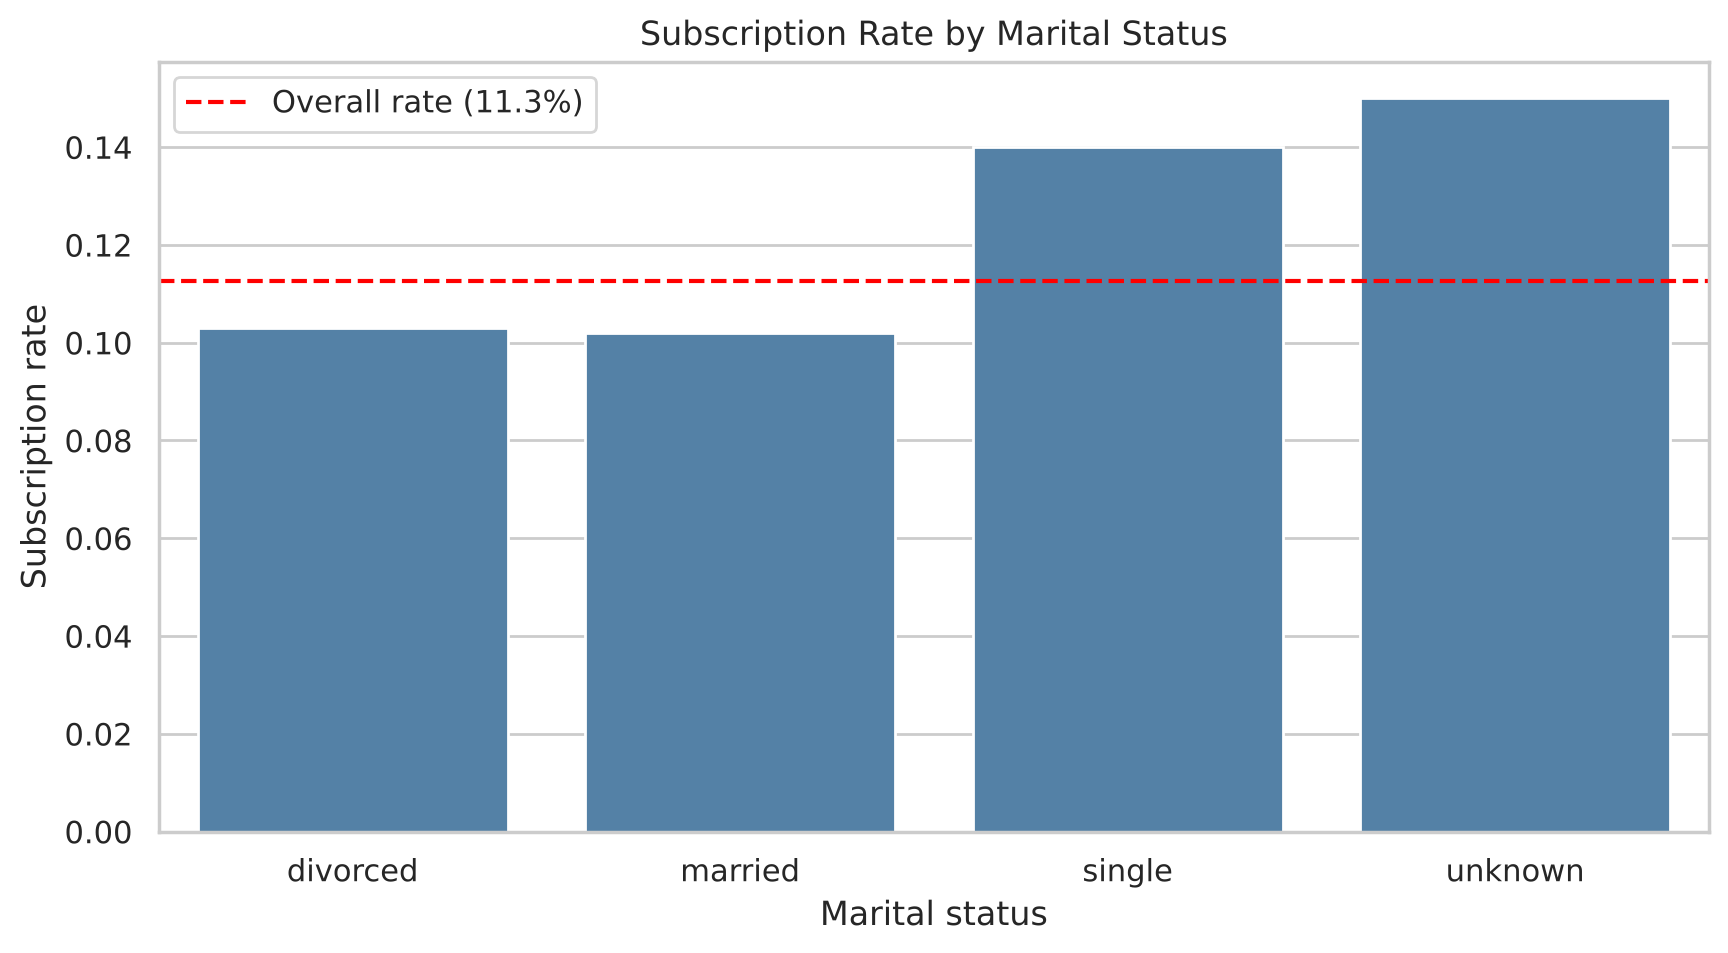

,records,subscribers,rate
marital,,,
divorced,4611,476,0.103
married,24921,2531,0.102
single,11564,1620,0.140
unknown,80,12,0.150


In [11]:
# Show the subscription rate by marital status
marital_table = rate_bar("marital", "Subscription Rate by Marital Status", "Marital status")
display(marital_table)

**Observation.** Single clients subscribe at 14.0% (1,620 of 11,564), against 10.2% for married clients (2,531 of 24,921) and 10.3% for divorced or widowed clients (476 of 4,611). The 80 'unknown' records show 15.0%, too few to interpret. **Business relevance:** the gap between the largest groups is about 4 percentage points. That is a modest signal and should not be the basis for targeting on its own.

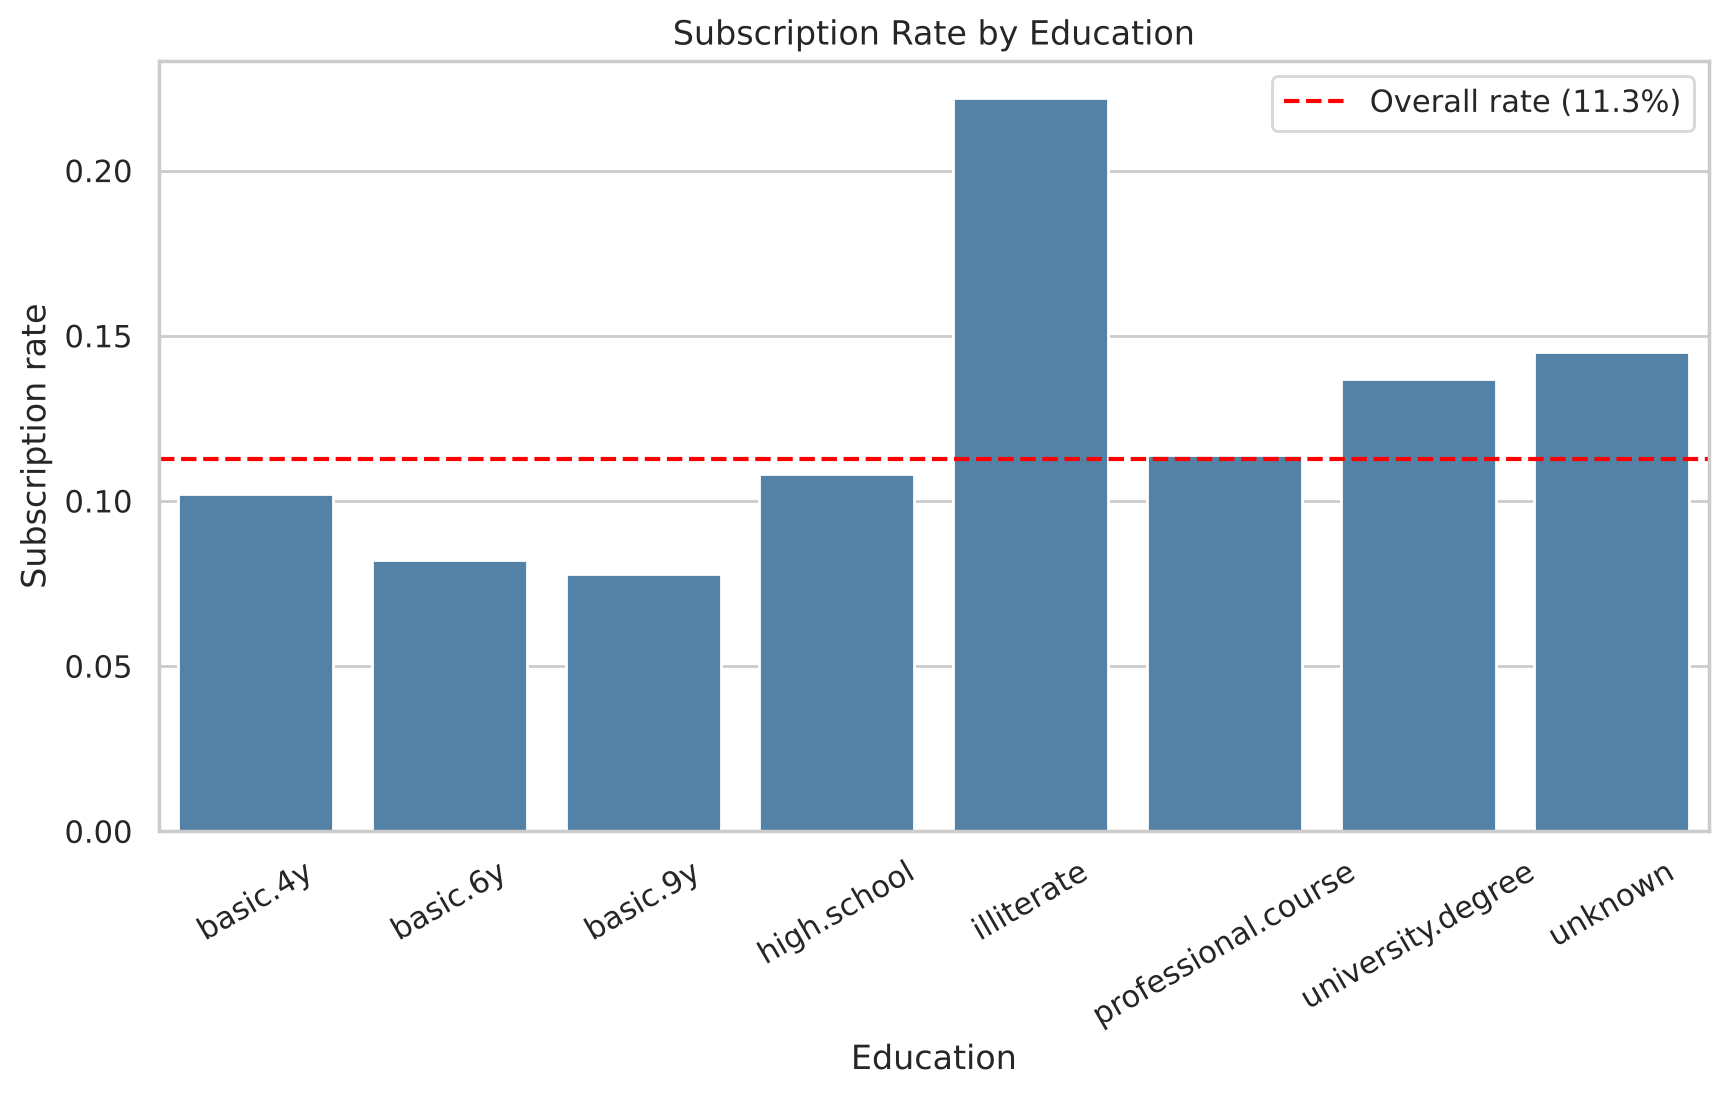

,records,subscribers,rate
education,,,
basic.4y,4176,428,0.102
basic.6y,2291,188,0.082
basic.9y,6045,473,0.078
high.school,9512,1031,0.108
illiterate,18,4,0.222
professional.course,5240,595,0.114
university.degree,12164,1669,0.137
unknown,1730,251,0.145


In [12]:
# Show the subscription rate by education level
education_table = rate_bar("education", "Subscription Rate by Education", "Education", rotate=30)
display(education_table)

**Observation.** University-degree holders subscribe at 13.7% (1,669 of 12,164), the highest of the large groups. Basic 9-year (7.8%, 473 of 6,045) and basic 6-year (8.2%, 188 of 2,291) are lowest. The 1,730 'unknown' records (4.2% of the data) show 14.5%, which is discussed in the unknown-category analysis below. Illiterate shows 22.2%, but on only 18 records. **Business relevance:** education follows the expected direction, but its gap of about 6 percentage points is smaller than the gaps for channel or prior outcome.

,records,subscribers,rate
contact,,,
cellular,26135,3852,0.147
telephone,15041,787,0.052


,records,subscribers,rate
housing,,,
no,18615,2025,0.109
unknown,990,107,0.108
yes,21571,2507,0.116


,records,subscribers,rate
loan,,,
no,33938,3849,0.113
unknown,990,107,0.108
yes,6248,683,0.109


,records,subscribers,rate
default,,,
no,32577,4196,0.129
unknown,8596,443,0.052
yes,3,0,0.000


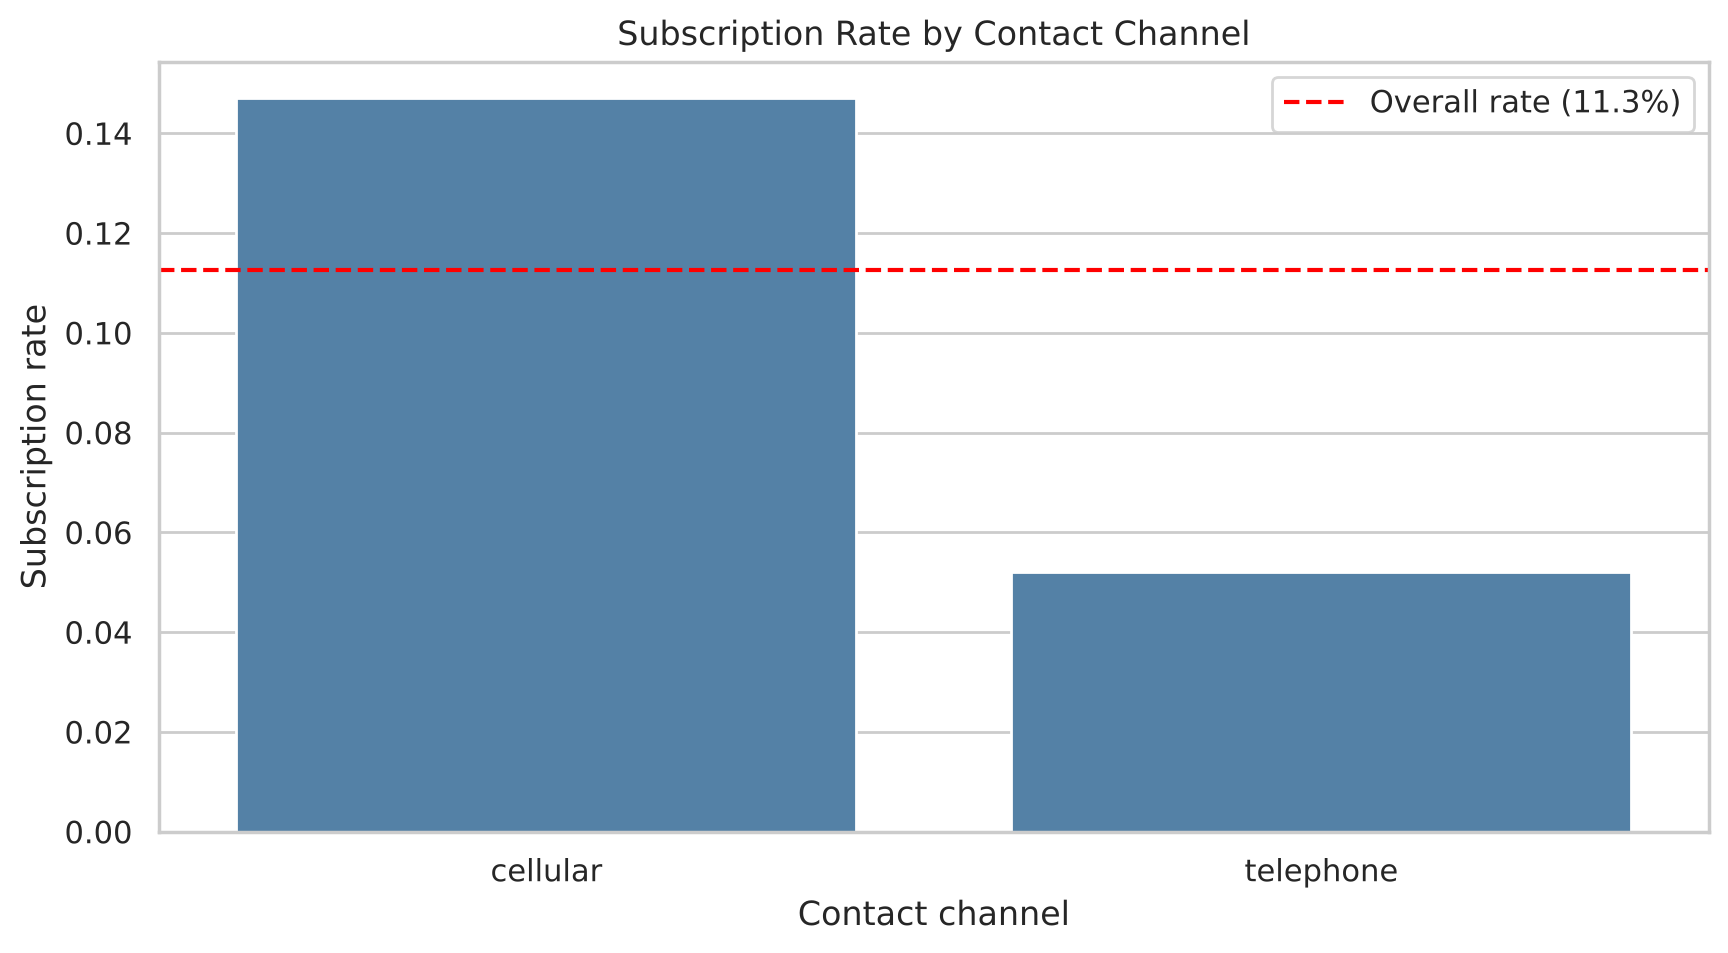

In [13]:
# Show the subscription rate by contact channel, and the loan and default fields
for col in ["contact", "housing", "loan", "default"]:
    display(subscription_rate(col))
contact_table = rate_bar("contact", "Subscription Rate by Contact Channel", "Contact channel")

**Observation.** Cellular contacts convert at 14.7% (3,852 of 26,135), against 5.2% for telephone (787 of 15,041), almost three times higher. Housing and personal-loan status show almost no difference (10.8% to 11.6%). Default status shows a gap: 'unknown' converts at 5.2% against 12.9% for a known 'no', and 'unknown' covers 8,596 records (20.9%). **Business relevance:** channel is the largest operational difference found. Channel was not randomly assigned, so this is an association, not a causal effect. Section 13 proposes a randomized test.

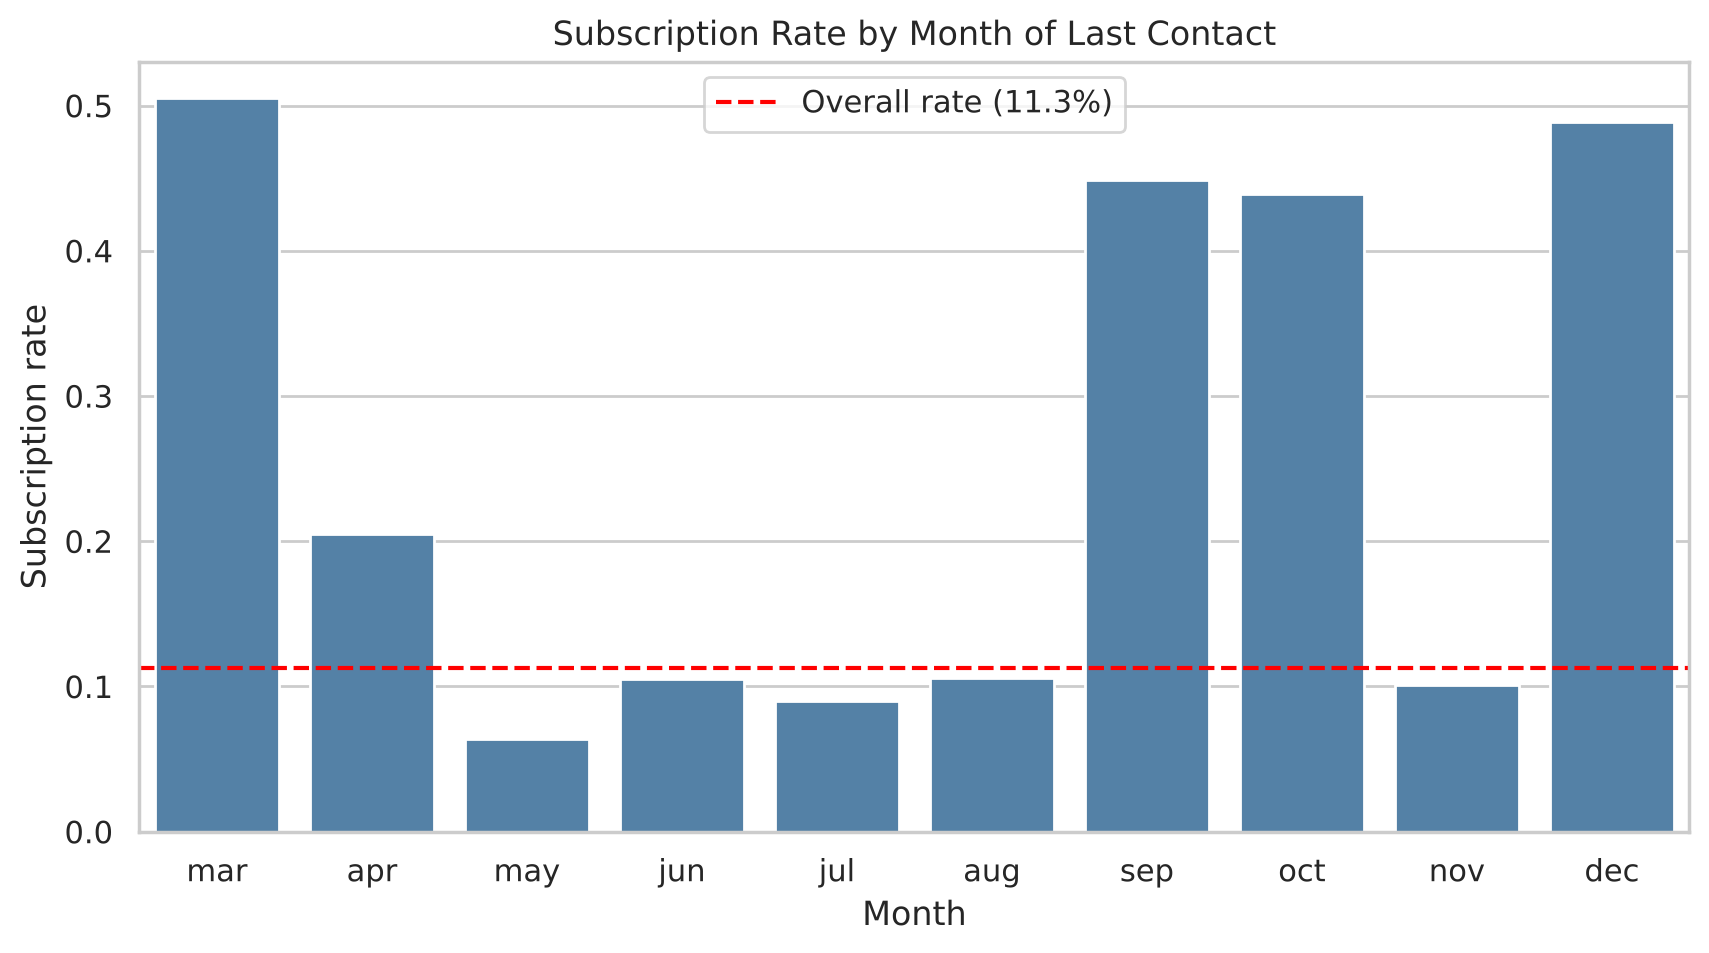

,records,subscribers,rate
month,,,
mar,546,276,0.505
apr,2631,539,0.205
may,13767,886,0.064
jun,5318,559,0.105
jul,7169,648,0.090
aug,6176,655,0.106
sep,570,256,0.449
oct,717,315,0.439
nov,4100,416,0.101


In [14]:
# Show the subscription rate by month of last contact, in calendar order
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_table = rate_bar("month", "Subscription Rate by Month of Last Contact", "Month", order=month_order)
display(month_table)

**Observation.** March (50.5%, 276 of 546), December (48.9%, 89 of 182), September (44.9%, 256 of 570) and October (43.9%, 315 of 717) have the highest rates. May has the lowest of the busy months at 6.4% (886 of 13,767). The four high-rate months contain only 182 to 717 records each. **Business relevance:** the timing pattern is large, but it coincides with the period shift shown in the time-block analysis below, and it may reflect which clients were called in those months. Month is also the strongest input in the production model's permutation importance (Section 9), so its effect should be tested, not assumed.

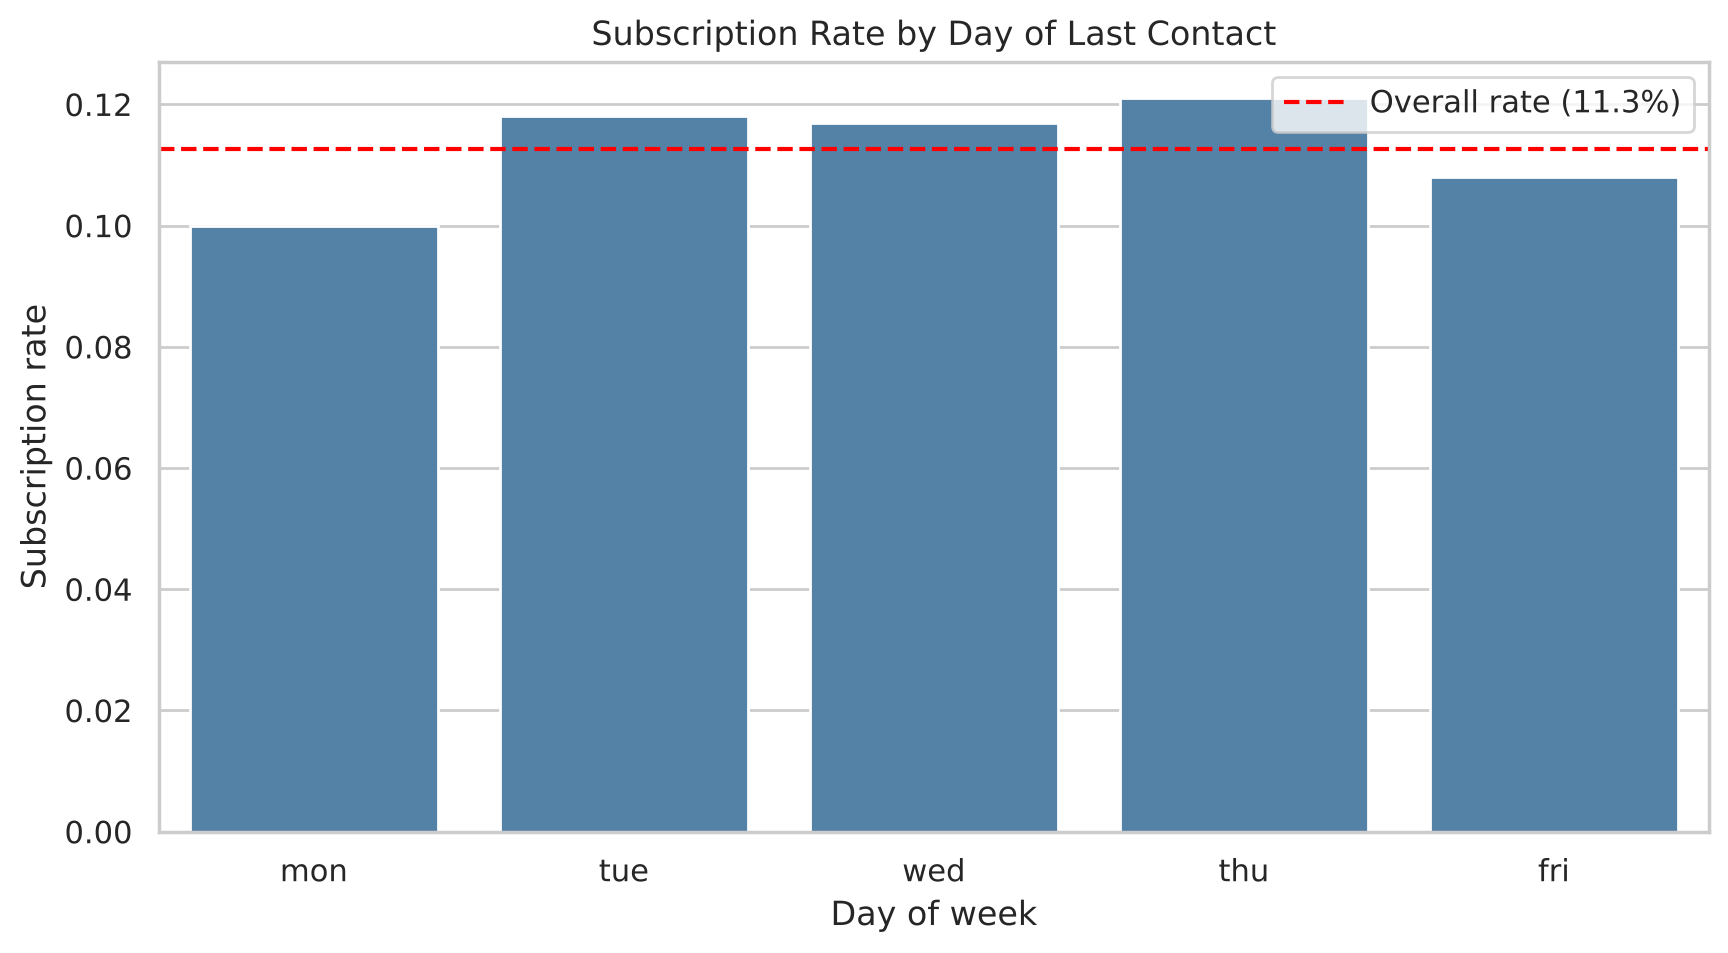

,records,subscribers,rate
day_of_week,,,
mon,8512,847,0.100
tue,8086,953,0.118
wed,8134,949,0.117
thu,8618,1044,0.121
fri,7826,846,0.108


In [15]:
# Show the subscription rate by day of the week of the last contact
day_order = ["mon", "tue", "wed", "thu", "fri"]
day_table = rate_bar("day_of_week", "Subscription Rate by Day of Last Contact", "Day of week", order=day_order)
display(day_table)

**Observation.** Day-of-week rates range from 10.0% (Monday) to 12.1% (Thursday), a spread of about 2 percentage points, with all five days close to the overall 11.3%. **Business relevance:** day of week has no practical value for targeting. The permutation importance in Section 9 agrees (it is near zero).

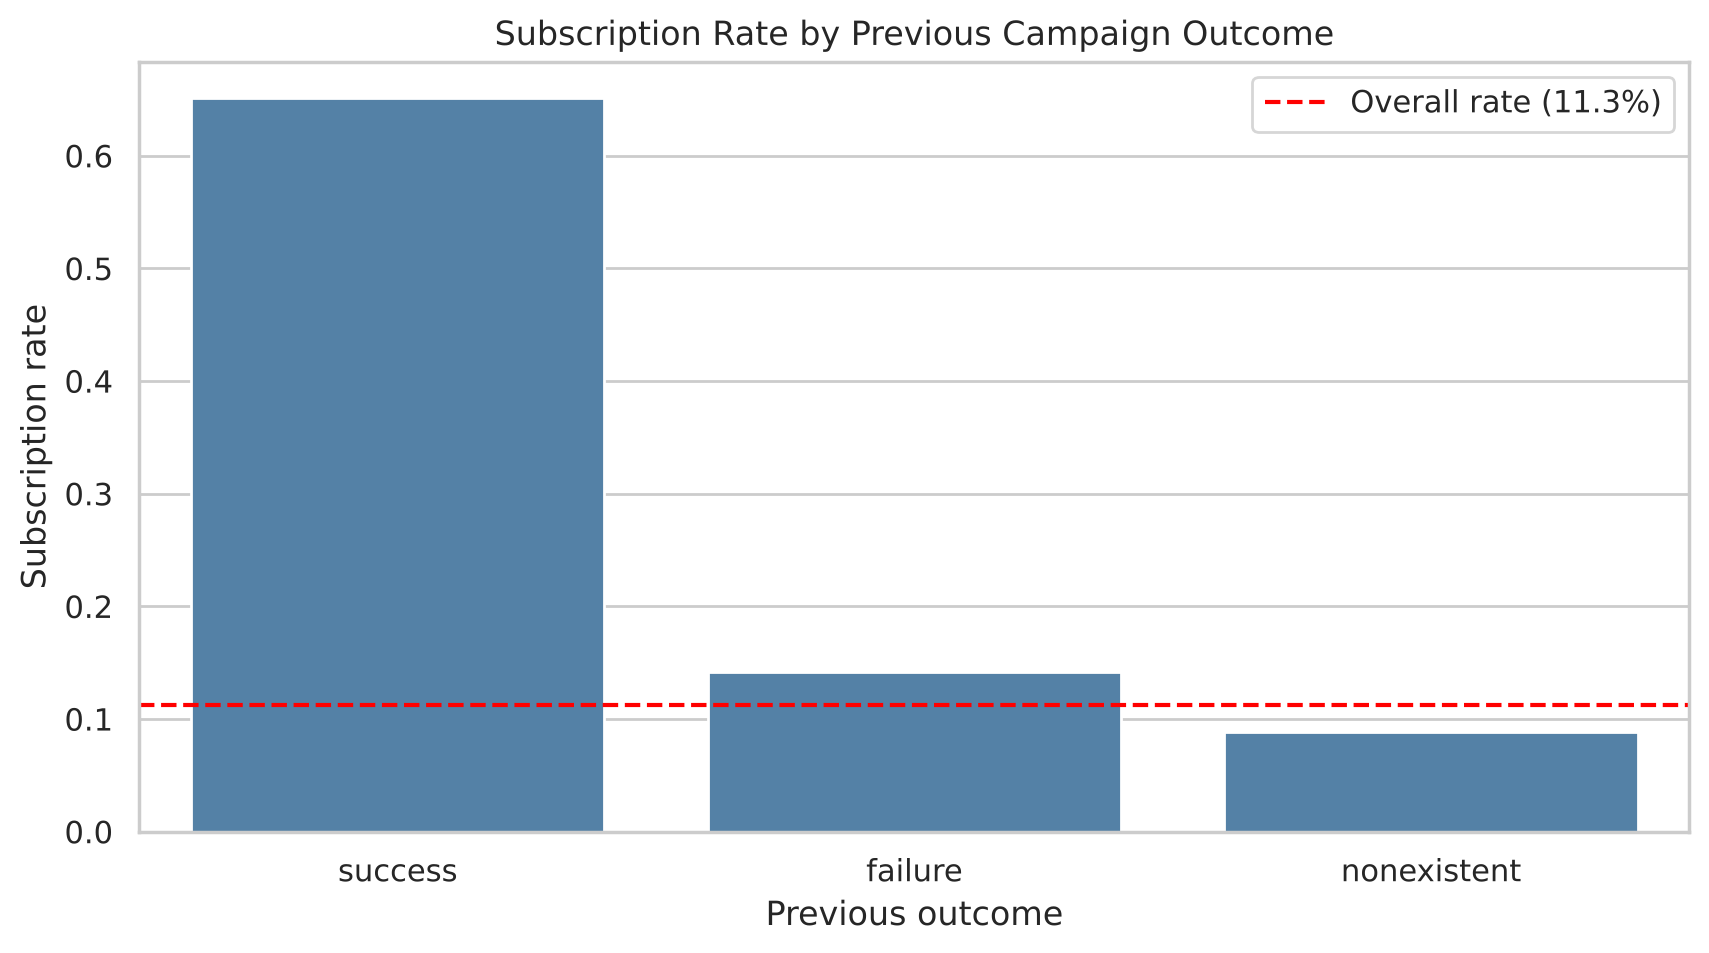

,records,subscribers,rate
poutcome,,,
success,1373,894,0.651
failure,4252,605,0.142
nonexistent,35551,3140,0.088


,records,rate
prev_capped,,
0,35551,0.088
1,4561,0.212
2,754,0.464
3,216,0.593
4,70,0.543
5,24,0.667


In [16]:
# Show the subscription rate by the outcome of the previous campaign
outcome_table = rate_bar("poutcome", "Subscription Rate by Previous Campaign Outcome", "Previous outcome",
                         order=["success", "failure", "nonexistent"])
display(outcome_table)

# Show the subscription rate by previous contacts, capped at 5
prev_table = df.assign(prev_capped=df["previous"].clip(upper=5)).groupby("prev_capped")["subscribed"].agg(
    records="size", rate="mean").round(3)
display(prev_table)

**Observation.** A previous successful campaign is the strongest signal in the file. Clients whose last campaign succeeded subscribe at 65.1% (894 of 1,373), against 14.2% after a failure and 8.8% for clients never contacted before. Clients contacted in any earlier campaign subscribe at 63.8% (967 of 1,515), against 9.3% (3,672 of 39,661) for those never contacted. **Business relevance:** earlier contact history is the clearest pre-call predictor available, and it is the natural first group to contact under any targeting policy.

,records,rate
c,,
0,17634,0.130
1,10568,0.115
2,5340,0.107
3,2650,0.094
4,1599,0.075
5,979,0.077
6,629,0.060
7,400,0.042
8,283,0.060


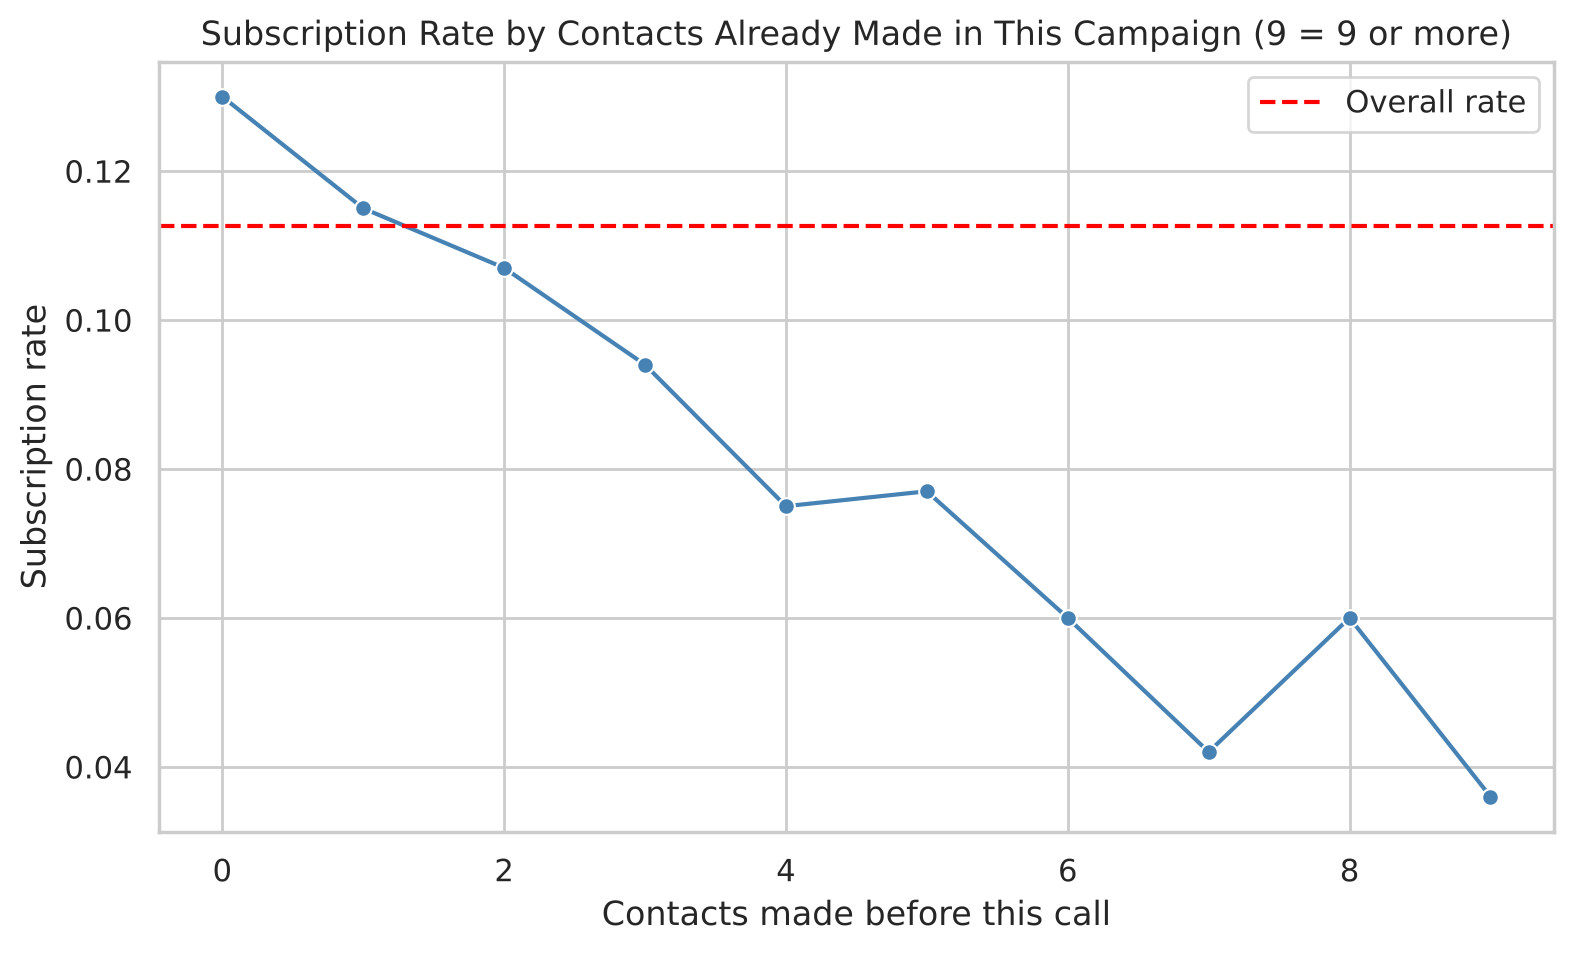

In [17]:
# Show the subscription rate by number of contacts already made in this campaign (capped at 10)
campaign_table = df.assign(c=df["contacts_before_call"].clip(upper=9)).groupby("c")["subscribed"].agg(
    records="size", rate="mean").round(3)
display(campaign_table)
plt.figure(figsize=(9, 5))
sns.lineplot(x=campaign_table.index, y=campaign_table["rate"], marker="o", color="steelblue")
plt.axhline(df["subscribed"].mean(), color="red", linestyle="--", label="Overall rate")
plt.title("Subscription Rate by Contacts Already Made in This Campaign (9 = 9 or more)")
plt.xlabel("Contacts made before this call")
plt.ylabel("Subscription rate")
plt.legend()
plt.show()

**Observation.** The subscription rate falls steadily with the number of calls already made in the campaign: 13.0% for a first call (17,634 records), 11.5% after one call, 10.7% after two, 9.4% after three, and 3.6% after nine or more (1,094 records, shown as 9). **Business relevance:** repeated calls to the same client show diminishing returns. This is an association: clients who were called repeatedly may differ in ways the data does not record. Section 13 proposes a randomized cap test.

,records,subscribers,rate
previously_contacted,,,
0,39661,3672,0.093
1,1515,967,0.638


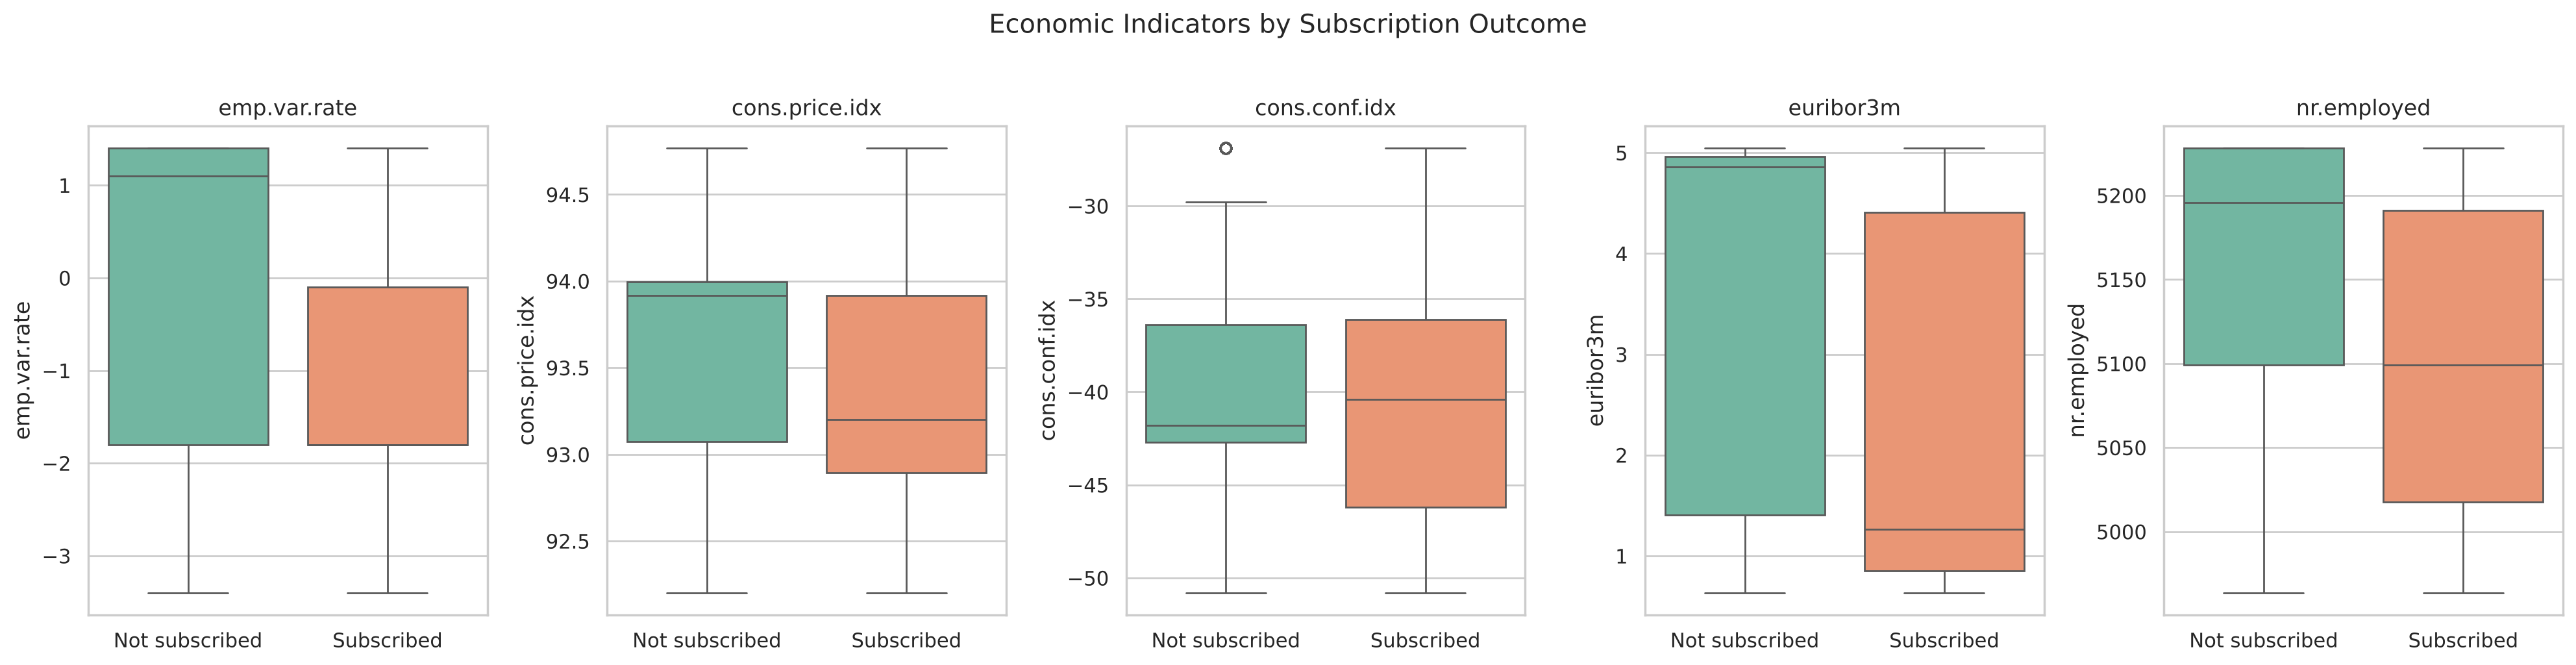

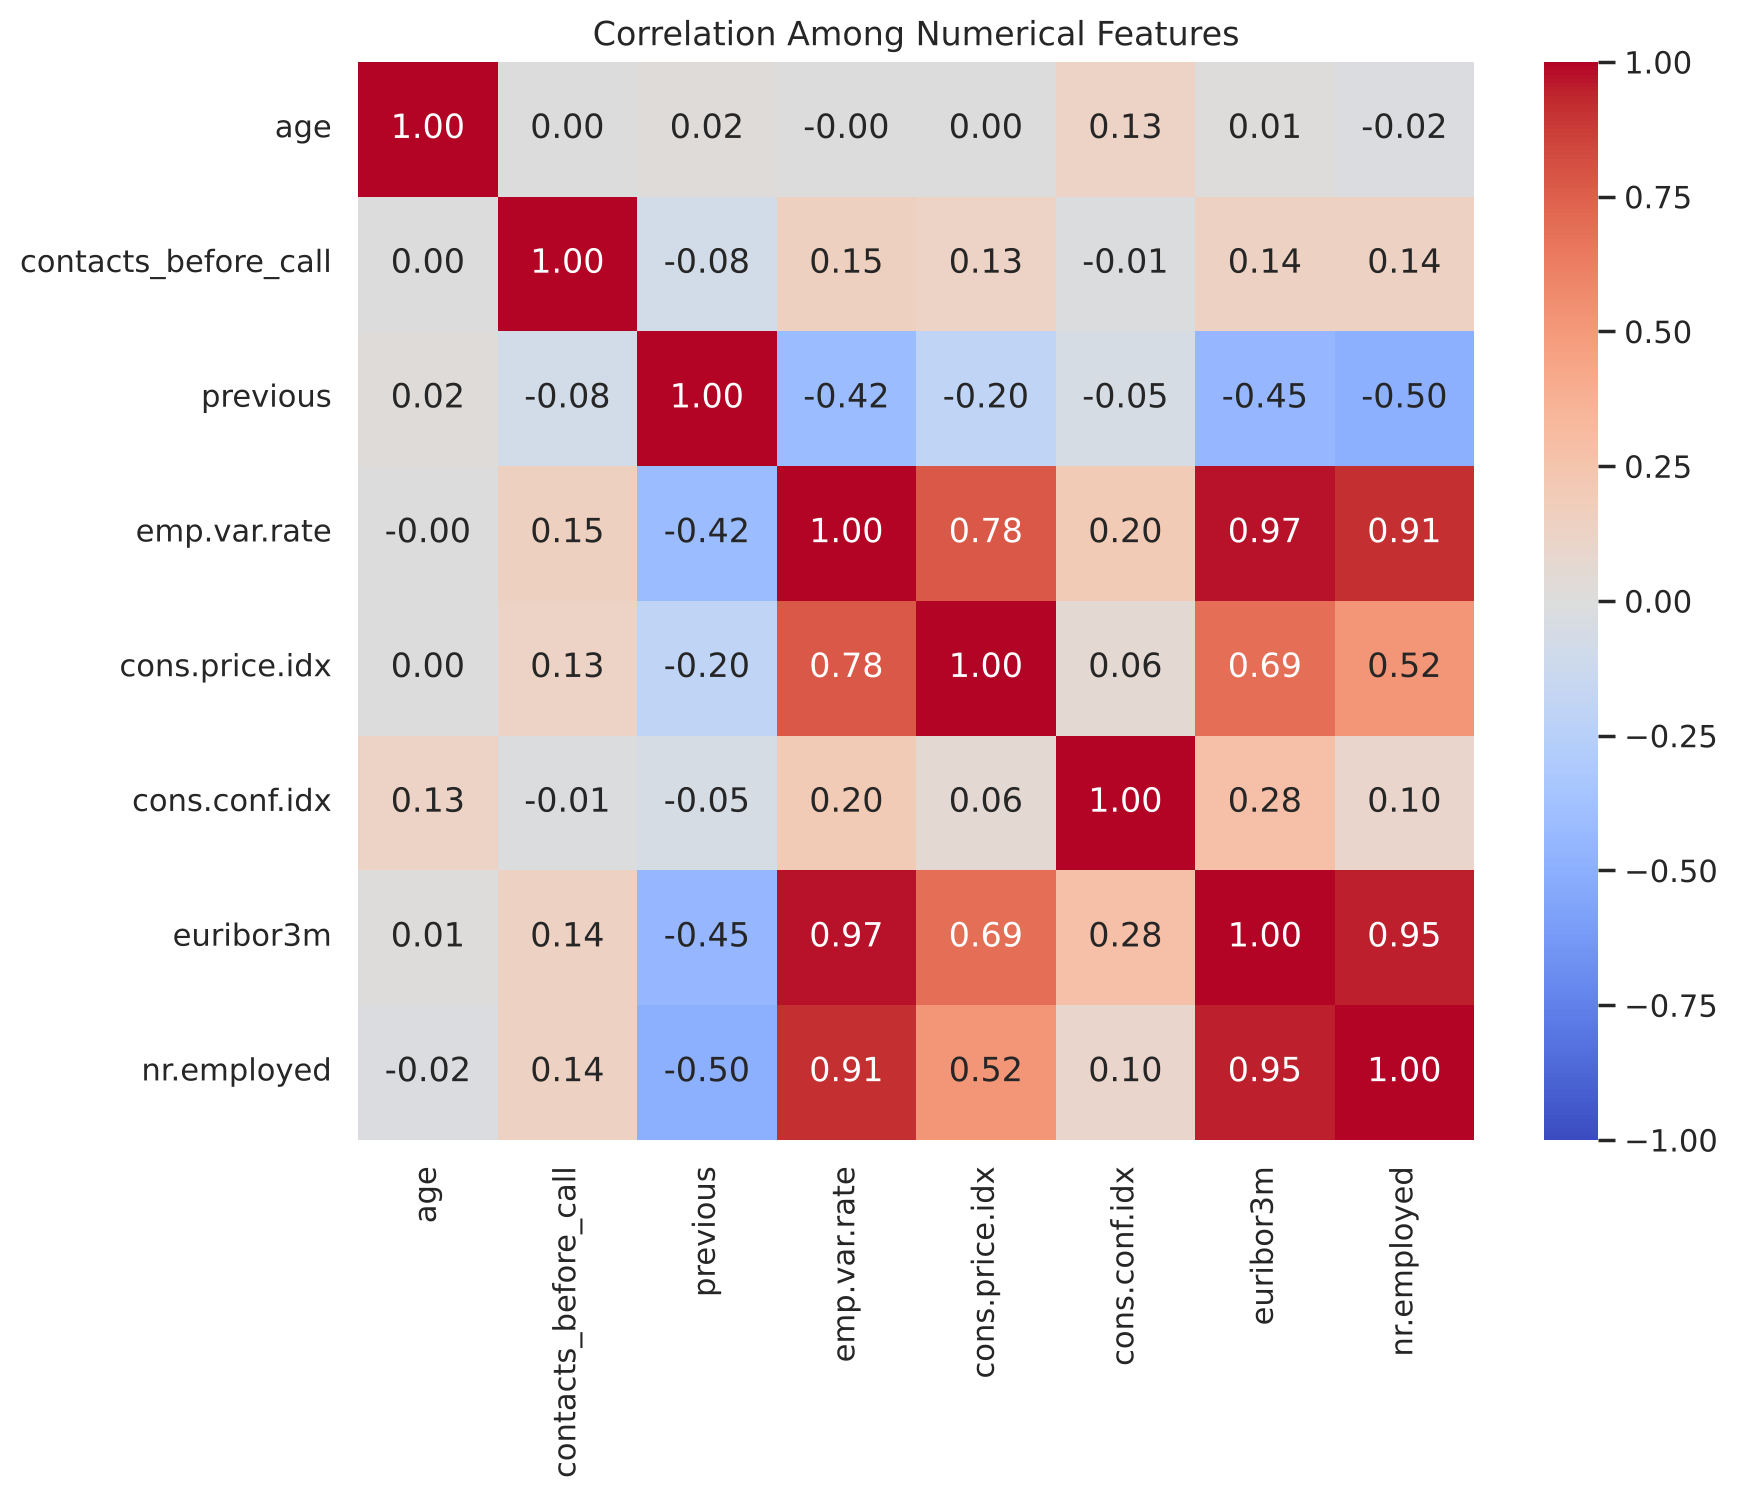

In [18]:
# Show the subscription rate by whether the client was contacted in an earlier campaign
display(subscription_rate("previously_contacted"))

# Show the economic indicators for subscribers and non-subscribers
outcome_label = df["subscribed"].map({0: "Not subscribed", 1: "Subscribed"})
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for ax, col in zip(axes, MACRO):
    sns.boxplot(x=outcome_label, y=df[col], ax=ax, hue=outcome_label, palette="Set2", legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Economic Indicators by Subscription Outcome", y=1.02)
plt.tight_layout()
plt.show()

# Show the correlation among numerical features
plt.figure(figsize=(9, 7))
sns.heatmap(df[NUM_CORE + MACRO].corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Among Numerical Features")
plt.show()

**Observation.** Subscribers differ on every macroeconomic indicator. Mean employment variation is −1.23 for subscribers against 0.25 for non-subscribers, mean Euribor is 2.12 against 3.81, and mean number employed is 5,095 against 5,176. The indicators are strongly correlated with each other (employment variation and Euribor 0.97, Euribor and number employed 0.95, employment variation and number employed 0.91). **Business relevance:** these indicators describe the economic period rather than individual clients. The fold-level and chronological results in Sections 5 to 7 show that they lift random-split accuracy but do not transfer forward in time, which is why the production model excludes them.

,records,rate
period_index,,
0,4118,0.028
1,4118,0.035
2,4117,0.042
3,4118,0.066
4,4117,0.062
5,4118,0.055
6,4118,0.102
7,4117,0.120
8,4118,0.157


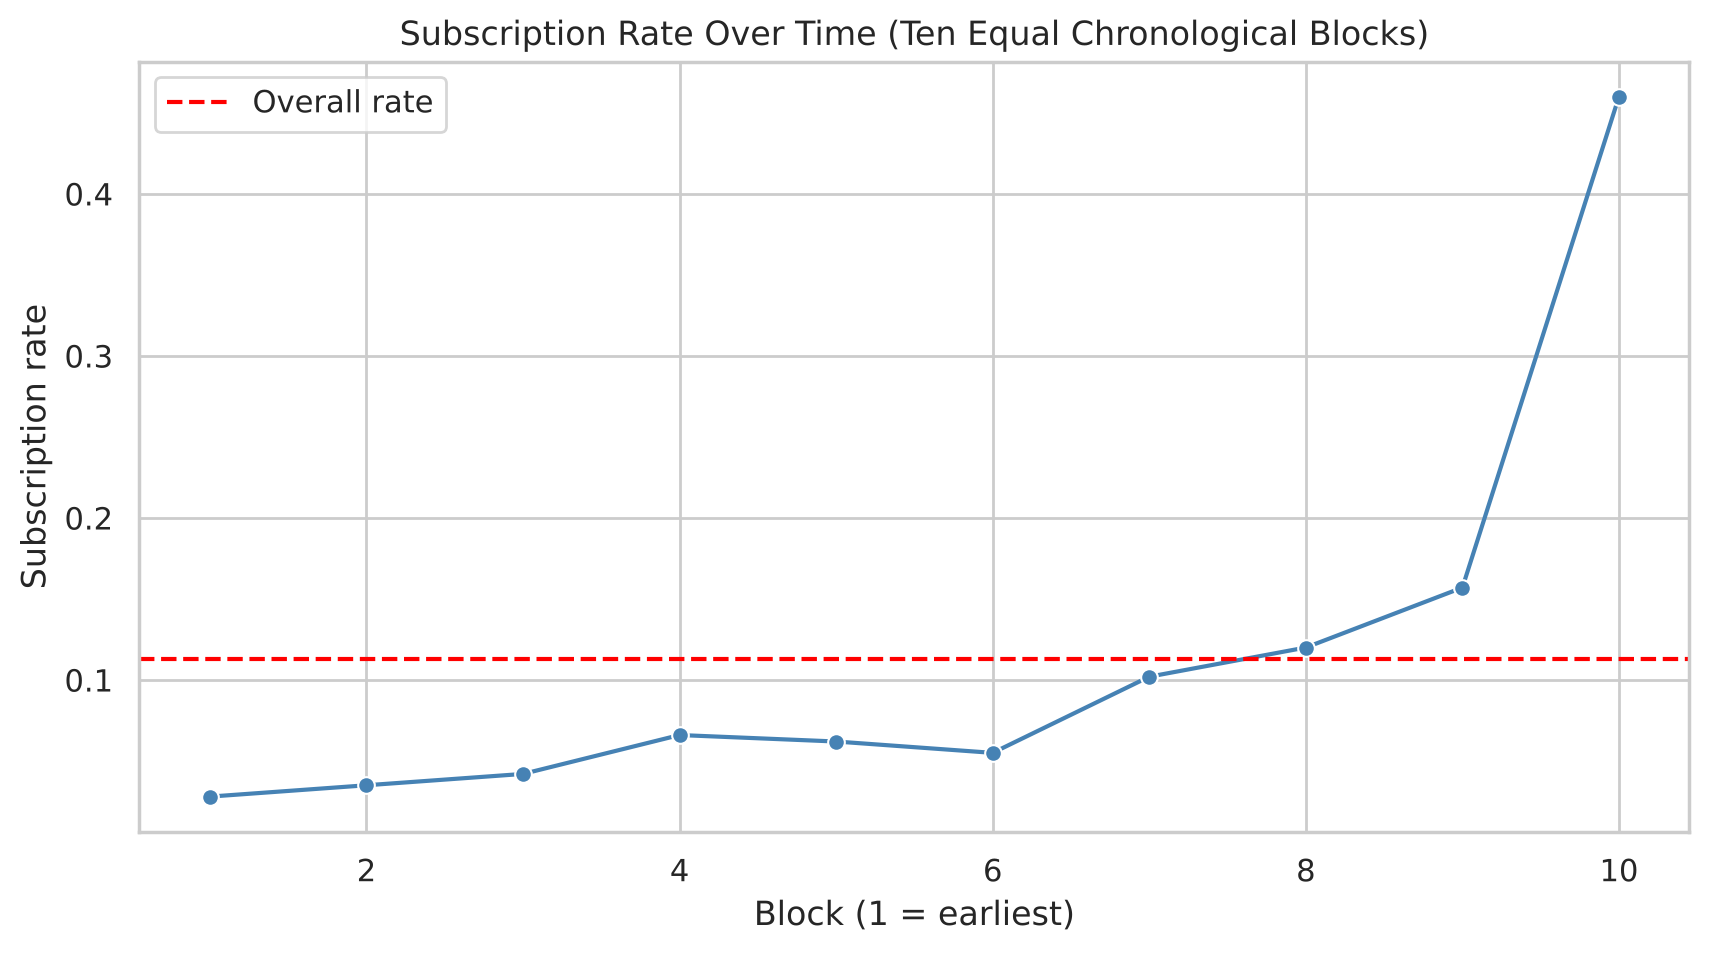

In [19]:
# Show how the subscription rate changes over time, in ten equal chronological blocks
block = df["period_index"] * 10 // len(df)
drift = df.groupby(block)["subscribed"].agg(records="size", rate="mean").round(3)
display(drift)
plt.figure(figsize=(10, 5))
sns.lineplot(x=drift.index + 1, y=drift["rate"], marker="o", color="steelblue")
plt.axhline(df["subscribed"].mean(), color="red", linestyle="--", label="Overall rate")
plt.title("Subscription Rate Over Time (Ten Equal Chronological Blocks)")
plt.xlabel("Block (1 = earliest)")
plt.ylabel("Subscription rate")
plt.legend()
plt.show()

**Observation.** The subscription rate rises from 2.8% in the first tenth of the file to 46.0% in the last tenth. The intermediate blocks are 3.5%, 4.2%, 6.6%, 6.2%, 5.5%, 10.2%, 12.0% and 15.7%. **Business relevance:** the campaign's response changed dramatically over the period. A model trained on earlier data will under-predict later periods. Section 8 confirms this on the chronological test set (mean predicted probability 0.18 against an observed 0.31). This is the most important practical fact in the file.

In [20]:
# Analyse the 'unknown' category: its size, its subscription rate, and whether those clients differ in age
UNKNOWN_COLS = ["job", "marital", "education", "default", "housing", "loan"]
rows = []
for c in UNKNOWN_COLS:
    u = df[c] == "unknown"
    rows.append([c, int(u.sum()), round(u.mean(), 4), round(df.loc[u, "subscribed"].mean(), 4),
                 round(df.loc[~u, "subscribed"].mean(), 4), round(df.loc[u, "age"].mean(), 1), round(df.loc[~u, "age"].mean(), 1)])
unknown_table = pd.DataFrame(rows, columns=["Column", "Unknown records", "Unknown share", "Rate if unknown",
                                            "Rate if known", "Mean age if unknown", "Mean age if known"])
display(unknown_table)

# Show how the share of 'unknown' default values changes over time
unknown_time = df.assign(u=(df["default"] == "unknown")).groupby(block)["u"].mean().round(3)
display(unknown_time.to_frame("Share of unknown 'default' values"))

,Column,Unknown records,Unknown share,Rate if unknown,Rate if known,Mean age if unknown,Mean age if known
0,job,330,0.0080,0.1121,0.1127,45.6,40.0
1,marital,80,0.0019,0.1500,0.1126,40.3,40.0
2,education,1730,0.0420,0.1451,0.1112,43.5,39.9
3,default,8596,0.2088,0.0515,0.1288,43.4,39.1
4,housing,990,0.0240,0.1081,0.1128,40.0,40.0
5,loan,990,0.0240,0.1081,0.1128,40.0,40.0


,Share of unknown 'default' values
period_index,
0,0.327
1,0.307
2,0.305
3,0.258
4,0.256
5,0.209
6,0.111
7,0.174
8,0.117


**Observation.** 'Unknown' values are concentrated in one part of the period: the share of 'unknown' default values falls from 32.7% in the first block to 2.4% in the last. In the unknown-category table, clients with unknown job, education or default are older on average than the rest (45.6, 43.5 and 43.4 years against 40.0, 39.9 and 39.1). Rates for unknown housing, loan and job are close to the overall rate, but unknown default converts at 5.2% against 12.9% for known values. **Treatment:** 'unknown' is kept as its own category and never imputed, so the model learns its rate. **Business relevance:** because unknown default is period-linked, it can carry period information, and it should not be read as a client trait.

poutcome,failure,nonexistent,success
contact,,,
cellular,0.144,0.117,0.652
telephone,0.113,0.047,0.641


poutcome,failure,nonexistent,success
contact,,,
cellular,3952,20913,1270
telephone,300,14638,103


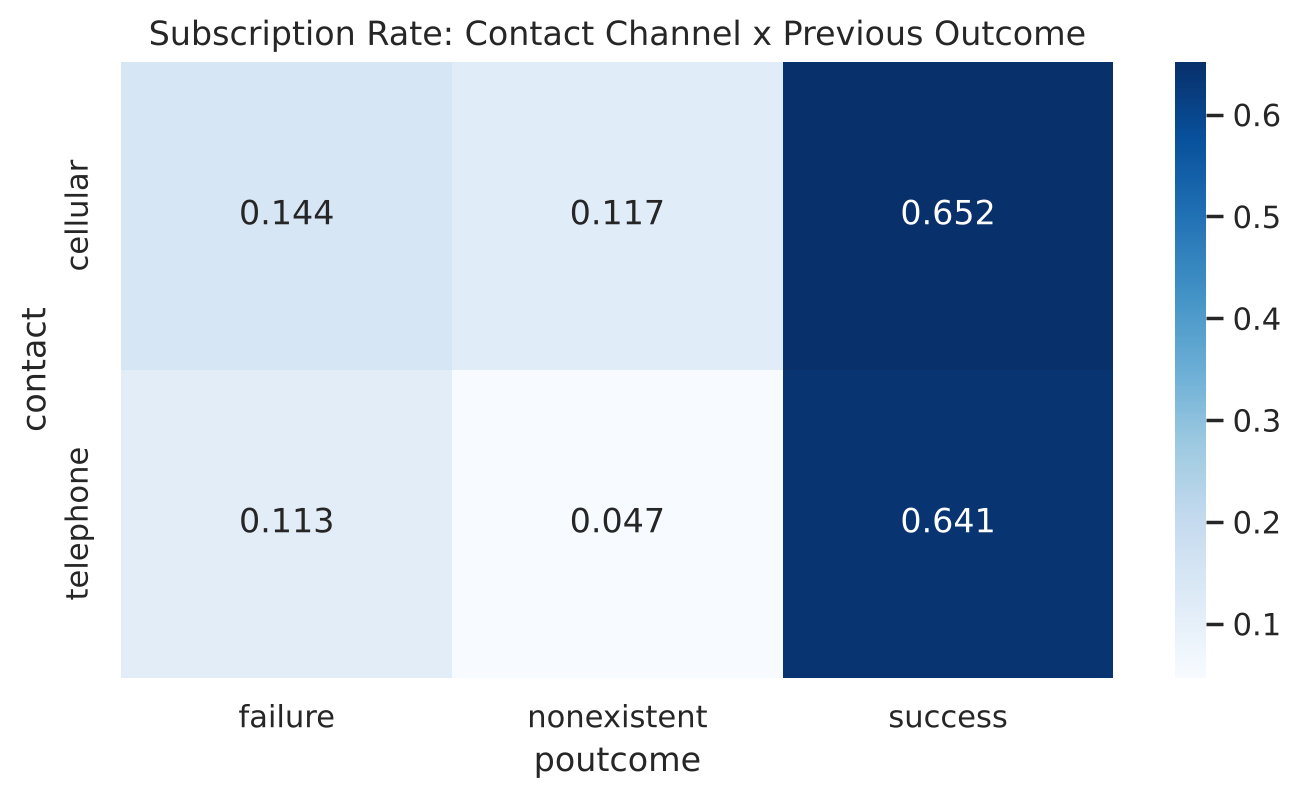

In [21]:
# Show the interaction between contact channel and previous outcome
interaction = df.pivot_table(index="contact", columns="poutcome", values="subscribed", aggfunc="mean").round(3)
counts_int = df.pivot_table(index="contact", columns="poutcome", values="subscribed", aggfunc="size")
display(interaction)
display(counts_int)
plt.figure(figsize=(8, 4))
sns.heatmap(interaction, annot=True, fmt=".3f", cmap="Blues")
plt.title("Subscription Rate: Contact Channel x Previous Outcome")
plt.show()

**Observation.** The channel gap depends on prior outcome. For clients with no previous campaign outcome, cellular converts at 11.7% (20,913 records) against 4.7% for telephone (14,638 records). For clients with a previous success, the two channels are almost equal (65.2% cellular, 1,270 records; 64.1% telephone, 103 records). **Business relevance:** for previous successes, channel makes little difference, while for new clients it matters most. A targeting rule can therefore treat the two groups differently. The cause is not established.

In [22]:
# Show outliers in contact counts and age, and report them without removing them
print("Clients with 10 or more contacts before this call:", int((df["contacts_before_call"] >= 10).sum()))
print("Clients aged over 70:", int((df["age"] > 70).sum()))
q1, q3 = df["age"].quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
print(f"Age IQR upper fence: {fence:.1f} | records above it: {int((df['age'] > fence).sum())}")
display(subscription_rate("age_group"))

Clients with 10 or more contacts before this call: 869
Clients aged over 70: 421
Age IQR upper fence: 69.5 | records above it: 468


,records,subscribers,rate
age_group,,,
18-25,1660,347,0.209
26-35,14844,1740,0.117
36-45,12839,1092,0.085
46-55,8247,717,0.087
56-65,2963,451,0.152
66+,618,290,0.469


**Outlier treatment.** The 869 clients with 10 or more prior calls have a subscription rate of 3.6% at nine or more calls, and the 468 clients above the age fence have a rate of 46.9% in the 66+ group. Neither group shows impossible values. Both are retained: removing the first would discard evidence on repeated calls, and removing the second would discard the strongest older-client signal.

## 3. Preprocessing, Feature Selection and Splits

In [23]:
# Build the preprocessing pipeline: scale numerical inputs and one-hot encode categorical inputs
def build_pipeline(model, num_cols, cat_cols=None):
    cat_cols = CAT if cat_cols is None else cat_cols
    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])
    return Pipeline([("prep", preprocessor), ("model", model)])

# Create the three chronological blocks and the development window
n = len(df)
cut_train, cut_val = int(0.6 * n), int(0.8 * n)
C_train, C_val, C_test = df.iloc[:cut_train], df.iloc[cut_train:cut_val], df.iloc[cut_val:]
D = df.iloc[:cut_val]
D_train, D_test = train_test_split(D, test_size=0.2, stratify=D["subscribed"], random_state=RANDOM_STATE)

# Report sizes and subscription rates for every block
split_report = pd.DataFrame({
    "Block": ["C_train (first 60%)", "C_val (next 20%)", "C_test (last 20%)", "D_train (random 80% of D)", "D_test (random 20% of D)"],
    "Records": [len(C_train), len(C_val), len(C_test), len(D_train), len(D_test)],
    "Subscription rate": [C_train.subscribed.mean(), C_val.subscribed.mean(), C_test.subscribed.mean(),
                          D_train.subscribed.mean(), D_test.subscribed.mean()],
}).round(4)
display(split_report)

,Block,Records,Subscription rate
0,C_train (first 60%),24705,0.0481
1,C_val (next 20%),8235,0.1107
2,C_test (last 20%),8236,0.3083
3,D_train (random 80% of D),26352,0.0638
4,D_test (random 20% of D),6588,0.0638


**Observation.** The chronological blocks differ sharply: 4.81% subscribed in the first 60% (C_train), 11.07% in the next 20% (C_val) and 30.83% in the last 20% (C_test). The random development block D has 6.38% in both its training and test parts. A random split of D therefore evaluates the model on a period similar to its training data, while C_test evaluates it on a much higher-rate period. **Business relevance:** the results a bank should expect depend on the period as much as on the model.

### Feature-by-feature preprocessing summary

| Feature | Type | Issue found | Treatment | Reason |
|---|---|---|---|---|
| `age` | Numerical | Skew 0.79; range 17–98 | Standardized | Tree and linear models both benefit from a common scale; no transform needed for this skew |
| `job` | Categorical (12) | 330 'unknown' (0.8%) | One-hot; 'unknown' kept as a level | Imputation would invent a value; the unknown rate is near average |
| `marital` | Categorical (4) | 80 'unknown' (0.2%) | One-hot; 'unknown' kept | Too few to matter, and keeping it avoids inventing a value |
| `education` | Categorical (8) | 1,730 'unknown' (4.2%); 18 'illiterate' | One-hot; 'unknown' kept | 'Unknown' rate (14.5%) differs from known groups, so it is informative |
| `default` | Categorical (3) | 8,596 'unknown' (20.9%); only 3 'yes' | One-hot; 'unknown' kept; rare 'yes' absorbed by encoder | 'Unknown' is strongly period-linked (Section 2); imputing it would hide that |
| `housing`, `loan` | Categorical | 990 'unknown' (2.4%) each | One-hot; 'unknown' kept | Rates are near average; keeping the level avoids dropping records |
| `contact` | Categorical (2) | None | One-hot | Strongest operational difference found; not randomly assigned |
| `month` | Categorical (10) | Uneven volumes (182 to 13,767) | One-hot | Timing effect is large but partly period-linked (Section 9) |
| `day_of_week` | Categorical (5) | None | One-hot | Spread about 2 points; kept for completeness |
| `campaign` → `contacts_before_call` | Numerical | Counts the current call; skew 4.76; maximum 56 | `campaign − 1` (calls already made); standardized | Pre-call information only; the shift does not change information content |
| `pdays` → `pdays_clean`, `previously_contacted` | Numerical with sentinel | 999 means never contacted (96.3%) | Flag plus −1 for never contacted; representation chosen on C_train (Section 3.1) | The sentinel would read as a large number of days |
| `previous` | Numerical | Skew 3.83; maximum 7 | Standardized | Counts are small; tails are real and retained |
| `poutcome` | Categorical (3) | 'nonexistent' is the majority (86.3%) | One-hot | Previous success is the strongest signal (Section 2) |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Numerical (macro) | Strong mutual correlation (0.52 to 0.97); conditional pre-call availability | Tested with and without; excluded from the production model | Lift the random-split score, do not transfer forward in time (Section 7) |
| `duration` | Numerical | Known only after the call | **Excluded**; benchmark only (Section 10) | Leakage |
| `subscribed` | Binary target | 11.27% positive | Target | — |

### 3.1 Feature selection on chronological training data only
All feature decisions use 5-fold stratified CV on C_train. Nothing from C_val, C_test, D_test is used here.

In [24]:
# Compare three pre-call representations of pdays, using CV on C_train only
fs_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
REPRESENTATIONS = {
    "raw pdays (999 sentinel)": ["pdays"],
    "cleaned pdays + flag": ["pdays_clean", "previously_contacted"],
    "flag only": ["previously_contacted"],
}

def fold_auc(make_model, cols, data):
    res = cross_validate(build_pipeline(make_model(), cols), data[cols + CAT], data["subscribed"],
                         cv=fs_cv, scoring="roc_auc")
    return res["test_score"]

make_lr = lambda: LogisticRegression(max_iter=3000)
make_gb = lambda: HistGradientBoostingClassifier(random_state=RANDOM_STATE, max_iter=300)

rep_rows = []
for rep, extra in REPRESENTATIONS.items():
    for fam, make in [("Logistic Regression", make_lr), ("Gradient Boosting", make_gb)]:
        s = fold_auc(make, NUM_CORE + MACRO + extra, C_train)
        rep_rows.append([rep, fam, s.mean(), s.std(ddof=1)])
rep_table = pd.DataFrame(rep_rows, columns=["pdays representation", "Model", "CV ROC-AUC", "CV SD"])
display(rep_table.round(6))

# Decision rule: choose the representation with the highest linear-model CV ROC-AUC.
# If the spread is below 0.001 (far below one CV SD), treat it as a tie and prefer the cleaned representation.
lr_rows = rep_table[rep_table["Model"] == "Logistic Regression"].set_index("pdays representation")
spread = lr_rows["CV ROC-AUC"].max() - lr_rows["CV ROC-AUC"].min()
lr_sd = lr_rows["CV SD"].mean()
print(f"Spread across representations (linear model): {spread:.6f} | average fold SD: {lr_sd:.4f}")
if spread < 0.001:
    REP_CHOSEN = "cleaned pdays + flag"
    print("Tie rule applied: spread below 0.001, cleaned representation chosen for interpretability.")
else:
    REP_CHOSEN = lr_rows["CV ROC-AUC"].idxmax()
print("Chosen pdays representation:", REP_CHOSEN)

,pdays representation,Model,CV ROC-AUC,CV SD
0,raw pdays (999 sentinel),Logistic Regression,0.593321,0.015574
1,raw pdays (999 sentinel),Gradient Boosting,0.599779,0.020027
2,cleaned pdays + flag,Logistic Regression,0.593437,0.016191
3,cleaned pdays + flag,Gradient Boosting,0.599779,0.020027
4,flag only,Logistic Regression,0.593078,0.015516
5,flag only,Gradient Boosting,0.599779,0.020027


Spread across representations (linear model): 0.000359 | average fold SD: 0.0158
Tie rule applied: spread below 0.001, cleaned representation chosen for interpretability.
Chosen pdays representation: cleaned pdays + flag


**Reading the result.** The three pdays representations differ by only 0.00036 in linear-model CV ROC-AUC (0.59308 to 0.59344), against a fold SD of about 0.016. The tie rule therefore applies, and the cleaned representation is used. Gradient boosting scores 0.59978 under all three representations, which confirms that the choice does not change model performance. The choice is about interpretability and the removal of the 999 sentinel, not about accuracy.

### 3.2 Interaction feature: adopted only if it clears a CV rule
Rule: adopt `cellular_x_prev_contact` if it raises the linear model's CV ROC-AUC by more than one fold SD and does not lower gradient boosting's CV ROC-AUC by more than one fold SD.

In [25]:
# Compare the chosen representation with and without the candidate interaction (C_train CV only)
base_extra = REPRESENTATIONS[REP_CHOSEN]
int_rows = []
for label, extra in [("without interaction", base_extra), ("with interaction", base_extra + ["cellular_x_prev_contact"])]:
    for fam, make in [("Logistic Regression", make_lr), ("Gradient Boosting", make_gb)]:
        s = fold_auc(make, NUM_CORE + MACRO + extra, C_train)
        int_rows.append([label, fam, s.mean(), s.std(ddof=1)])
int_table = pd.DataFrame(int_rows, columns=["Variant", "Model", "CV ROC-AUC", "CV SD"])
display(int_table.round(6))

lr_no = int_table[(int_table.Variant == "without interaction") & (int_table.Model == "Logistic Regression")].iloc[0]
lr_yes = int_table[(int_table.Variant == "with interaction") & (int_table.Model == "Logistic Regression")].iloc[0]
gb_no = int_table[(int_table.Variant == "without interaction") & (int_table.Model == "Gradient Boosting")].iloc[0]
gb_yes = int_table[(int_table.Variant == "with interaction") & (int_table.Model == "Gradient Boosting")].iloc[0]
lr_gain_ok = (lr_yes["CV ROC-AUC"] - lr_no["CV ROC-AUC"]) > lr_no["CV SD"]
gb_not_hurt = (gb_yes["CV ROC-AUC"] - gb_no["CV ROC-AUC"]) > -gb_no["CV SD"]
USE_INTERACTION = bool(lr_gain_ok and gb_not_hurt)
print("LR gain above one SD:", bool(lr_gain_ok), "| GB not hurt beyond one SD:", bool(gb_not_hurt))
print("Interaction adopted:", USE_INTERACTION)

# Define the two input sets: with and without macroeconomic indicators
extra_inputs = base_extra + (["cellular_x_prev_contact"] if USE_INTERACTION else [])
VARIANTS = {
    "with macro": NUM_CORE + MACRO + extra_inputs,
    "without macro": NUM_CORE + extra_inputs,
}
print("Input set 'with macro':", VARIANTS["with macro"])
print("Input set 'without macro':", VARIANTS["without macro"])

,Variant,Model,CV ROC-AUC,CV SD
0,without interaction,Logistic Regression,0.593437,0.016191
1,without interaction,Gradient Boosting,0.599779,0.020027
2,with interaction,Logistic Regression,0.593079,0.016705
3,with interaction,Gradient Boosting,0.599779,0.020027


LR gain above one SD: False | GB not hurt beyond one SD: True
Interaction adopted: False
Input set 'with macro': ['age', 'contacts_before_call', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'pdays_clean', 'previously_contacted']
Input set 'without macro': ['age', 'contacts_before_call', 'previous', 'pdays_clean', 'previously_contacted']


**Reading the result.** Adding the cellular-by-prior-contact interaction does not raise linear-model CV ROC-AUC (0.59344 without, 0.59308 with), and gradient boosting is unchanged (0.59978 both). The rule excludes the interaction. The descriptive channel-by-outcome pattern (Section 2) is still reported.

## 4. Candidate Models and Search Spaces

In [26]:
# Define each model family: how to build it, its tuning grid, and its scikit-learn default settings
def configs(grid):
    keys = list(grid)
    return [dict(zip(keys, values)) for values in itertools.product(*[grid[k] for k in keys])]

def cfg_str(params):
    return ", ".join(f"{k}={v}" for k, v in params.items())

FAMILIES = {
    "Logistic Regression": {
        "make": lambda p: LogisticRegression(max_iter=3000, **p),
        "grid": {"C": [0.01, 0.1, 1, 10, 100]},
        "default": {"C": 1.0},
    },
    "Random Forest": {
        "make": lambda p: RandomForestClassifier(n_estimators=200,
                                                 random_state=RANDOM_STATE, n_jobs=-1, **p),
        "grid": {"max_depth": [6, 12], "min_samples_leaf": [10, 30]},
        "default": {"max_depth": None, "min_samples_leaf": 1},
    },
    "Gradient Boosting": {
        "make": lambda p: HistGradientBoostingClassifier(random_state=RANDOM_STATE, max_iter=300, **p),
        "grid": {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [15, 31], "min_samples_leaf": [20, 60]},
        "default": {"learning_rate": 0.1, "max_leaf_nodes": 31, "min_samples_leaf": 20},
    },
}
KEYS = [(f, v) for f in FAMILIES for v in VARIANTS]
search_grid = pd.DataFrame([[f, len(configs(FAMILIES[f]["grid"]))] for f in FAMILIES], columns=["Family", "Grid points"])
display(search_grid)

,Family,Grid points
0,Logistic Regression,5
1,Random Forest,4
2,Gradient Boosting,8


## 5. Hyperparameter Search (validation only)
Random protocol: 5-fold CV inside D_train. Chronological protocol: fit on C_train, score on C_val. The test sets are not referenced here.

In [27]:
# Random protocol: fold-level CV on D_train for every configuration, including the defaults
cv_D = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rand_rows = []
for family, spec in FAMILIES.items():
    for variant, cols in VARIANTS.items():
        for params in [spec["default"]] + configs(spec["grid"]):
            res = cross_validate(build_pipeline(spec["make"](params), cols), D_train[cols + CAT],
                                 D_train["subscribed"], cv=cv_D, scoring="roc_auc")
            folds = res["test_score"]
            rand_rows.append({"Family": family, "Variant": variant, "Config": cfg_str(params),
                              "Is default": params is spec["default"], "params": params,
                              **{f"Fold {i+1}": folds[i] for i in range(5)},
                              "CV mean": folds.mean(), "CV SD": folds.std(ddof=1)})
rand_search = pd.DataFrame(rand_rows)
display(rand_search[["Family", "Variant", "Config", "Is default", "CV mean", "CV SD"]].round(4))

,Family,Variant,Config,Is default,CV mean,CV SD
0,Logistic Regression,with macro,C=1.0,True,0.6709,0.0074
1,Logistic Regression,with macro,C=0.01,False,0.6700,0.0075
2,Logistic Regression,with macro,C=0.1,False,0.6710,0.0070
3,Logistic Regression,with macro,C=1,False,0.6709,0.0074
4,Logistic Regression,with macro,C=10,False,0.6711,0.0076
5,Logistic Regression,with macro,C=100,False,0.6711,0.0076
6,Logistic Regression,without macro,C=1.0,True,0.6655,0.0074
7,Logistic Regression,without macro,C=0.01,False,0.6633,0.0071
8,Logistic Regression,without macro,C=0.1,False,0.6651,0.0071
9,Logistic Regression,without macro,C=1,False,0.6655,0.0074


In [28]:
# Chronological protocol: fit on C_train, score on C_val (ROC-AUC for ranking, PR-AUC for information)
chrono_rows = []
for family, spec in FAMILIES.items():
    for variant, cols in VARIANTS.items():
        for params in [spec["default"]] + configs(spec["grid"]):
            model = build_pipeline(spec["make"](params), cols).fit(C_train[cols + CAT], C_train["subscribed"])
            p_val = model.predict_proba(C_val[cols + CAT])[:, 1]
            chrono_rows.append({"Family": family, "Variant": variant, "Config": cfg_str(params),
                                "Is default": params is spec["default"], "params": params,
                                "Val ROC-AUC": roc_auc_score(C_val["subscribed"], p_val),
                                "Val PR-AUC": average_precision_score(C_val["subscribed"], p_val)})
chrono_search = pd.DataFrame(chrono_rows)
display(chrono_search[["Family", "Variant", "Config", "Is default", "Val ROC-AUC", "Val PR-AUC"]].round(4))

,Family,Variant,Config,Is default,Val ROC-AUC,Val PR-AUC
0,Logistic Regression,with macro,C=1.0,True,0.4752,0.0972
1,Logistic Regression,with macro,C=0.01,False,0.4841,0.0992
2,Logistic Regression,with macro,C=0.1,False,0.4744,0.0976
3,Logistic Regression,with macro,C=1,False,0.4752,0.0972
4,Logistic Regression,with macro,C=10,False,0.4757,0.0978
5,Logistic Regression,with macro,C=100,False,0.4762,0.0973
6,Logistic Regression,without macro,C=1.0,True,0.6337,0.1929
7,Logistic Regression,without macro,C=0.01,False,0.5941,0.1525
8,Logistic Regression,without macro,C=0.1,False,0.5967,0.1610
9,Logistic Regression,without macro,C=1,False,0.6337,0.1929


In [29]:
# Select the tuned configuration for each family and variant, separately for each protocol.
# Random protocol: highest CV mean. Chronological protocol: highest validation ROC-AUC.
params_random, params_chrono, tuning_rows = {}, {}, []
for f, v in KEYS:
    r = rand_search[(rand_search.Family == f) & (rand_search.Variant == v) & (~rand_search["Is default"])]
    c = chrono_search[(chrono_search.Family == f) & (chrono_search.Variant == v) & (~chrono_search["Is default"])]
    best_r = r.loc[r["CV mean"].idxmax()]
    best_c = c.loc[c["Val ROC-AUC"].idxmax()]
    params_random[(f, v)] = best_r["params"]
    params_chrono[(f, v)] = best_c["params"]
    d_r = rand_search[(rand_search.Family == f) & (rand_search.Variant == v) & (rand_search["Is default"])].iloc[0]
    d_c = chrono_search[(chrono_search.Family == f) & (chrono_search.Variant == v) & (chrono_search["Is default"])].iloc[0]
    tuning_rows.append([f, v, cfg_str(d_r["params"]), d_r["CV mean"], d_c["Val ROC-AUC"],
                        best_r["Config"], best_r["CV mean"], best_c["Config"], best_c["Val ROC-AUC"]])
tuning_table = pd.DataFrame(tuning_rows, columns=["Family", "Variant", "Default config", "Default CV AUC",
                                                  "Default val AUC", "Tuned config (random)", "Tuned CV AUC",
                                                  "Tuned config (chrono)", "Tuned val AUC"])
print("Before-and-after tuning comparison")
display(tuning_table.round(4))

Before-and-after tuning comparison


,Family,Variant,Default config,Default CV AUC,Default val AUC,Tuned config (random),Tuned CV AUC,Tuned config (chrono),Tuned val AUC
0,Logistic Regression,with macro,C=1.0,0.6709,0.4752,C=100,0.6711,C=0.01,0.4841
1,Logistic Regression,without macro,C=1.0,0.6655,0.6337,C=1,0.6655,C=10,0.6389
2,Random Forest,with macro,"max_depth=None, min_samples_leaf=1",0.6430,0.5361,"max_depth=6, min_samples_leaf=30",0.6821,"max_depth=6, min_samples_leaf=10",0.5957
3,Random Forest,without macro,"max_depth=None, min_samples_leaf=1",0.6345,0.4872,"max_depth=12, min_samples_leaf=10",0.6762,"max_depth=12, min_samples_leaf=30",0.5220
4,Gradient Boosting,with macro,"learning_rate=0.1, max_leaf_nodes=31, min_samp...",0.6858,0.4590,"learning_rate=0.03, max_leaf_nodes=15, min_sam...",0.6892,"learning_rate=0.1, max_leaf_nodes=31, min_samp...",0.4590
5,Gradient Boosting,without macro,"learning_rate=0.1, max_leaf_nodes=31, min_samp...",0.6739,0.5145,"learning_rate=0.03, max_leaf_nodes=15, min_sam...",0.6797,"learning_rate=0.03, max_leaf_nodes=15, min_sam...",0.5303


**Reading the before-and-after comparison.** On the random protocol, tuning helped the random forest (fold-mean CV ROC-AUC from 0.643 to 0.682 with macro inputs, and from 0.635 to 0.676 without) and gradient boosting without macro inputs (0.674 to 0.680). Logistic regression with macro inputs gained only 0.0002 (its default C = 1 was nearly optimal), and without macro inputs it did not change. On the chronological validation period, tuning changed little: logistic regression without macro inputs rose from 0.634 to 0.639, and the random forest with macro inputs from 0.536 to 0.596. Gradient boosting with macro inputs kept its default configuration, with validation ROC-AUC 0.459. **Interpretation:** tuning can improve fit within a period, but it cannot make a model learn a shift that the training data does not contain.

In [30]:
# Show the fold-level cross-validation results for the tuned random-protocol configurations
fold_rows = []
for f, v in KEYS:
    row = rand_search[(rand_search.Family == f) & (rand_search.Variant == v) & (rand_search.Config == cfg_str(params_random[(f, v)]))].iloc[0]
    fold_rows.append([f, v, row["Config"], row["Fold 1"], row["Fold 2"], row["Fold 3"], row["Fold 4"], row["Fold 5"],
                      row["CV mean"], row["CV SD"], row["CV SD"] / np.sqrt(5)])
fold_table = pd.DataFrame(fold_rows, columns=["Family", "Variant", "Config", "Fold 1", "Fold 2", "Fold 3", "Fold 4",
                                              "Fold 5", "Mean", "SD", "Standard error"])
display(fold_table.round(4))

,Family,Variant,Config,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,SD,Standard error
0,Logistic Regression,with macro,C=100,0.6742,0.6613,0.6801,0.6654,0.6745,0.6711,0.0076,0.0034
1,Logistic Regression,without macro,C=1,0.6651,0.6550,0.6752,0.6637,0.6685,0.6655,0.0074,0.0033
2,Random Forest,with macro,"max_depth=6, min_samples_leaf=30",0.6827,0.6899,0.6851,0.6641,0.6887,0.6821,0.0105,0.0047
3,Random Forest,without macro,"max_depth=12, min_samples_leaf=10",0.6725,0.6832,0.6846,0.6662,0.6745,0.6762,0.0077,0.0034
4,Gradient Boosting,with macro,"learning_rate=0.03, max_leaf_nodes=15, min_sam...",0.6875,0.6850,0.6875,0.6861,0.6998,0.6892,0.0060,0.0027
5,Gradient Boosting,without macro,"learning_rate=0.03, max_leaf_nodes=15, min_sam...",0.6774,0.6714,0.6899,0.6771,0.6828,0.6797,0.0070,0.0031


**Fold-level variability.** For the random-protocol tuned configurations, fold means fall between 0.666 and 0.689 with fold SDs of 0.006 to 0.011, and standard errors of 0.003 to 0.005 (SD divided by √5). The gap between the best and worst families is about 0.02, roughly four to six standard errors, so the ranking is stable within the period. The absolute level is low: within the development window, the models separate buyers only modestly. The random-protocol winners do not hold up forward in time (Section 7).

## 6. Model Selection (validation evidence only)
Rule, declared before the final test is opened: (1) each family and variant keeps its chronological-validation-best configuration; (2) among these candidates, keep those whose random-protocol CV mean is within one fold SD of the best random-protocol CV mean; (3) of those, choose the highest chronological validation ROC-AUC.

In [31]:
# Apply the selection rule using only CV and validation scores
sel_rows = []
for f, v in KEYS:
    r_best = rand_search[(rand_search.Family == f) & (rand_search.Variant == v) & (~rand_search["Is default"])]
    row_c = r_best[r_best.Config == cfg_str(params_chrono[(f, v)])].iloc[0]
    v_best = chrono_search[(chrono_search.Family == f) & (chrono_search.Variant == v) & (~chrono_search["Is default"])]
    val_auc = v_best[v_best.Config == cfg_str(params_chrono[(f, v)])]["Val ROC-AUC"].iloc[0]
    sel_rows.append({"Family": f, "Variant": v, "Chrono config": cfg_str(params_chrono[(f, v)]),
                     "Random CV mean": row_c["CV mean"], "Random CV SD": row_c["CV SD"],
                     "Chrono val ROC-AUC": val_auc})
sel_table = pd.DataFrame(sel_rows)
best_rcv = sel_table["Random CV mean"].max()
best_rsd = sel_table.loc[sel_table["Random CV mean"].idxmax(), "Random CV SD"]
sel_table["Within 1 SD of best CV"] = sel_table["Random CV mean"] >= best_rcv - best_rsd
display(sel_table.round(4))

# Step 1: the originally declared rule (random-CV filter, then validation AUC)
eligible = sel_table[sel_table["Within 1 SD of best CV"]]
declared = eligible.loc[eligible["Chrono val ROC-AUC"].idxmax()]
print("ORIGINALLY DECLARED RULE selects:", declared["Family"], f"({declared['Variant']})")
print(f"  its validation ROC-AUC: {declared['Chrono val ROC-AUC']:.4f} (below 0.5 means worse than chance on the validation period)")

# Step 2: REVISED rule, adopted after reviewing validation results (test set not used).
# Deployment is forward in time, so the chronological validation AUC is the decisive evidence.
# Random-fold CV is reported but does not decide, because it rewards identifying the period.
chosen_row = sel_table.loc[sel_table["Chrono val ROC-AUC"].idxmax()]
PROD_KEY = (chosen_row["Family"], chosen_row["Variant"])
print("REVISED RULE selects:", PROD_KEY)
print("Chronological config:", chosen_row["Chrono config"])
print(f"Validation ROC-AUC: {chosen_row['Chrono val ROC-AUC']:.4f} | Random CV: {chosen_row['Random CV mean']:.4f} +/- {chosen_row['Random CV SD']:.4f}")

,Family,Variant,Chrono config,Random CV mean,Random CV SD,Chrono val ROC-AUC,Within 1 SD of best CV
0,Logistic Regression,with macro,C=0.01,0.6700,0.0075,0.4841,False
1,Logistic Regression,without macro,C=10,0.6654,0.0074,0.6389,False
2,Random Forest,with macro,"max_depth=6, min_samples_leaf=10",0.6815,0.0094,0.5957,False
3,Random Forest,without macro,"max_depth=12, min_samples_leaf=30",0.6757,0.0067,0.5220,False
4,Gradient Boosting,with macro,"learning_rate=0.1, max_leaf_nodes=31, min_samp...",0.6858,0.0027,0.4590,True
5,Gradient Boosting,without macro,"learning_rate=0.03, max_leaf_nodes=15, min_sam...",0.6767,0.0081,0.5303,False


ORIGINALLY DECLARED RULE selects: Gradient Boosting (with macro)
  its validation ROC-AUC: 0.4590 (below 0.5 means worse than chance on the validation period)
REVISED RULE selects: ('Logistic Regression', 'without macro')
Chronological config: C=10
Validation ROC-AUC: 0.6389 | Random CV: 0.6654 +/- 0.0074


**Selection rule: declared, tested, and revised.** The rule declared at the outset was to keep candidates within one fold SD of the best random-protocol CV, and then choose the highest chronological validation ROC-AUC. Applied as declared, it selects gradient boosting with macro inputs, whose validation ROC-AUC is 0.459, below chance. That outcome exposed a flaw: the random-CV filter rewards identifying the period, and the validation step then cannot recover. The rule was **revised on validation evidence only**: choose the candidate with the highest chronological validation ROC-AUC across all candidates. This keeps the test set out of the decision. The change is disclosed here and in the change report. The revised choice is logistic regression without macro inputs (C = 10): validation ROC-AUC 0.639, random CV 0.665 ± 0.007. Its macro-free design also removes the conditional pre-call availability problem for the production model.

## 7. Final Evaluation on Held-Out Test Sets
Each test set is scored once, after all choices above are fixed. Bootstrap intervals (1,000 resamples) quantify uncertainty.

In [32]:
# Define bootstrap helpers for any metric that takes true labels and scores
def bootstrap_ci(y_true, scores, metric):
    y_true, scores = np.asarray(y_true), np.asarray(scores)
    idx = rng.integers(0, len(y_true), size=(N_BOOT, len(y_true)))
    values = np.array([metric(y_true[i], scores[i]) for i in idx])
    return np.percentile(values, [2.5, 97.5])

def topk_metrics(y_true, scores, frac):
    k = int(round(len(y_true) * frac))
    top = np.argsort(-scores, kind="stable")[:k]
    captured = y_true[top].sum()
    precision = captured / k
    return precision, captured / y_true.sum(), precision / y_true.mean()

# Random protocol: tuned models fit on D_train, scored on D_test; also scored on C_test for a fair cross-protocol comparison
# (D_train lies entirely before C_test, so no test information is used)
rand_test_D, rand_test_C = {}, {}
for f, v in KEYS:
    m = build_pipeline(FAMILIES[f]["make"](params_random[(f, v)]), VARIANTS[v]).fit(
        D_train[VARIANTS[v] + CAT], D_train["subscribed"])
    rand_test_D[(f, v)] = m.predict_proba(D_test[VARIANTS[v] + CAT])[:, 1]
    rand_test_C[(f, v)] = m.predict_proba(C_test[VARIANTS[v] + CAT])[:, 1]

# Chronological protocol: threshold from C_val (model fit on C_train), then refit on C_train + C_val and score C_test once
chrono_models, chrono_test, thresholds = {}, {}, {}
C_trainval = df.iloc[:cut_val]
for f, v in KEYS:
    cols = VARIANTS[v]
    fit_train = build_pipeline(FAMILIES[f]["make"](params_chrono[(f, v)]), cols).fit(C_train[cols + CAT], C_train["subscribed"])
    p_val = fit_train.predict_proba(C_val[cols + CAT])[:, 1]
    prec, rec, thr = precision_recall_curve(C_val["subscribed"], p_val)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    thresholds[(f, v)] = thr[np.argmax(f1)]
    final = build_pipeline(FAMILIES[f]["make"](params_chrono[(f, v)]), cols).fit(C_trainval[cols + CAT], C_trainval["subscribed"])
    chrono_models[(f, v)] = final
    chrono_test[(f, v)] = final.predict_proba(C_test[cols + CAT])[:, 1]

In [33]:
# Compare every candidate on the SAME chronological test set, under both training regimes
y_Ctest = C_test["subscribed"].values
y_Dtest = D_test["subscribed"].values
comp_rows = []
for f, v in KEYS:
    ci_r = bootstrap_ci(y_Ctest, rand_test_C[(f, v)], roc_auc_score)
    ci_c = bootstrap_ci(y_Ctest, chrono_test[(f, v)], roc_auc_score)
    comp_rows.append({
        "Model": f"{f} ({v})",
        "Random-protocol CV AUC": round(sel_table.set_index(["Family", "Variant"]).loc[(f, v), "Random CV mean"], 4),
        "Random-protocol test AUC (D_test)": round(roc_auc_score(y_Dtest, rand_test_D[(f, v)]), 4),
        "Random-trained on C_test AUC": round(roc_auc_score(y_Ctest, rand_test_C[(f, v)]), 4),
        "Chrono-trained on C_test AUC": round(roc_auc_score(y_Ctest, chrono_test[(f, v)]), 4),
        "Chrono-trained 95% CI": f"[{ci_c[0]:.3f}, {ci_c[1]:.3f}]",
        "Chrono-trained PR-AUC": round(average_precision_score(y_Ctest, chrono_test[(f, v)]), 4),
    })
comp_table = pd.DataFrame(comp_rows)
display(comp_table)
print(f"Base rate on C_test: {y_Ctest.mean():.4f} | base rate on D_test: {y_Dtest.mean():.4f}")

,Model,Random-protocol CV AUC,Random-protocol test AUC (D_test),Random-trained on C_test AUC,Chrono-trained on C_test AUC,Chrono-trained 95% CI,Chrono-trained PR-AUC
0,Logistic Regression (with macro),0.6700,0.6627,0.7458,0.7049,"[0.692, 0.716]",0.5401
1,Logistic Regression (without macro),0.6654,0.6591,0.6996,0.7001,"[0.687, 0.713]",0.4950
2,Random Forest (with macro),0.6815,0.6746,0.7400,0.7413,"[0.730, 0.753]",0.5371
3,Random Forest (without macro),0.6757,0.6667,0.6915,0.6973,"[0.684, 0.709]",0.5190
4,Gradient Boosting (with macro),0.6858,0.6884,0.6344,0.6522,"[0.640, 0.666]",0.4411
5,Gradient Boosting (without macro),0.6767,0.6758,0.6787,0.6704,"[0.658, 0.683]",0.4532


Base rate on C_test: 0.3083 | base rate on D_test: 0.0638


**Reading the common-test comparison.** Every candidate is scored on the same chronological test set (C_test, base rate 30.83%). Chronologically trained models range from 0.652 (gradient boosting with macro inputs) to 0.741 (random forest with macro inputs), and the selected model scores 0.700 (95% CI 0.689 to 0.712, from the headline bootstrap). The random forest with macro inputs has the highest test AUC, but it was **not** selected: its validation ROC-AUC was 0.596, against 0.639 for the selected model, and the test result was not used to choose. The random-trained models score 0.66 to 0.69 on D_test, which is lower than the chronological models' test scores on C_test, because D_test has a base rate of 6.4% and weak within-period signal. The cross-protocol columns differ in two ways: training window (random 80% of D against all of D) and tuning rule. Read them as purpose-specific estimates, not as a single like-for-like contest.

### 7.1 Production model summary
The production candidate is the one chosen in Section 6. Its chronological model is refitted on C_train + C_val and its threshold was set on C_val.

In [34]:
# Name the production model and its fixed components
prod_model = chrono_models[PROD_KEY]
prod_threshold = thresholds[PROD_KEY]
prod_cols = VARIANTS[PROD_KEY[1]]
prod_proba = chrono_test[PROD_KEY]
print("Production model:", f"{PROD_KEY[0]} ({PROD_KEY[1]})")
print("Config:", cfg_str(params_chrono[PROD_KEY]))
print(f"Decision threshold (max F1 on C_val): {prod_threshold:.4f}")
print("Inputs:", prod_cols + CAT)

Production model: Logistic Regression (without macro)
Config: C=10
Decision threshold (max F1 on C_val): 0.0950
Inputs: ['age', 'contacts_before_call', 'previous', 'pdays_clean', 'previously_contacted', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


## 8. Production Model: Targeting, Threshold, Calibration and Uncertainty
Everything in this section refers to the same production model, evaluated on the chronological test set.

,Threshold,Value,Accuracy,Precision,Recall,F1,Clients flagged
0,Default 0.5,0.500,0.6961,0.5200,0.1839,0.2717,898
1,Chosen threshold (from C_val),0.095,0.6903,0.4981,0.6187,0.5519,3154


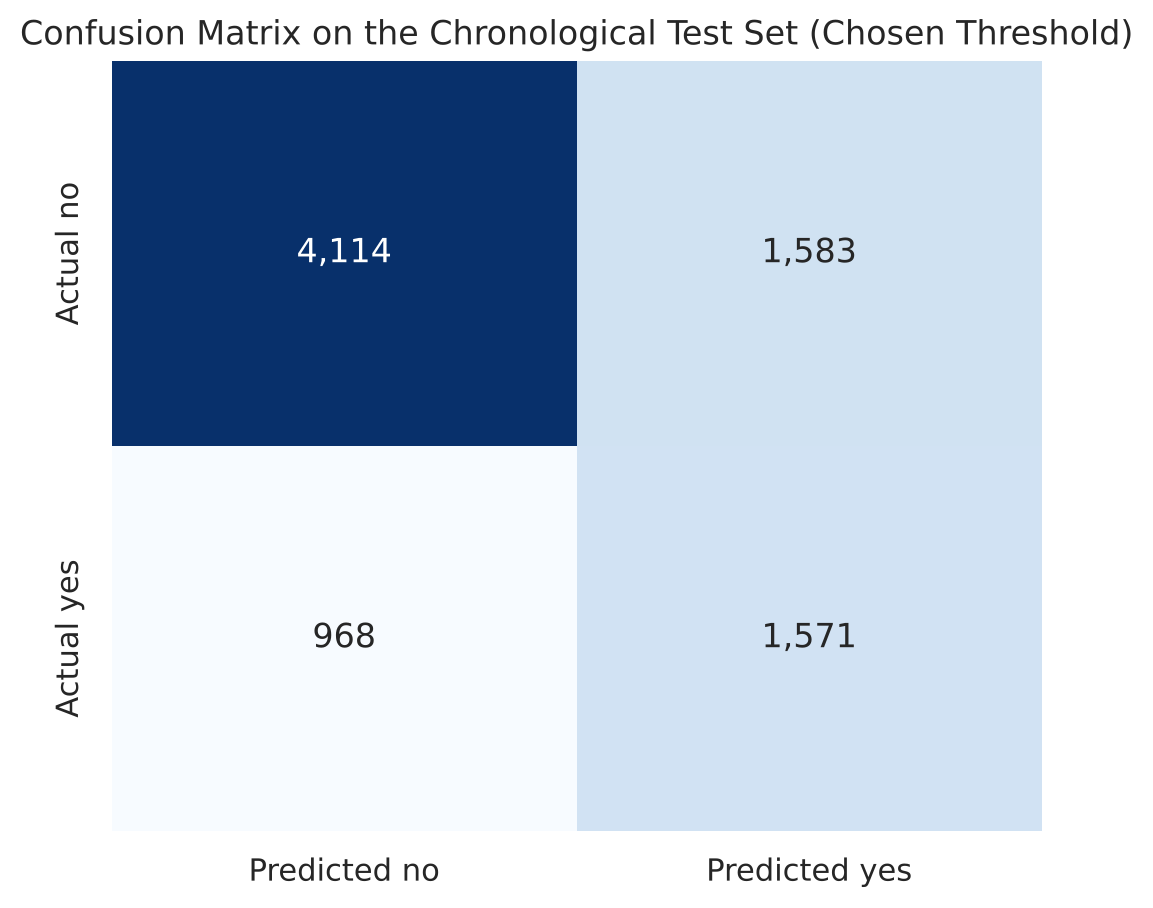

In [35]:
# Report the threshold result on the chronological test set, with a 0.5 default for comparison
rows = []
for label, t in [("Default 0.5", 0.5), ("Chosen threshold (from C_val)", prod_threshold)]:
    pred = (prod_proba >= t).astype(int)
    rows.append([label, round(t, 4), accuracy_score(y_Ctest, pred), precision_score(y_Ctest, pred, zero_division=0),
                 recall_score(y_Ctest, pred), f1_score(y_Ctest, pred, zero_division=0), int(pred.sum())])
thr_table = pd.DataFrame(rows, columns=["Threshold", "Value", "Accuracy", "Precision", "Recall", "F1", "Clients flagged"]).round(4)
display(thr_table)

# Show the confusion matrix at the chosen threshold
cm = confusion_matrix(y_Ctest, (prod_proba >= prod_threshold).astype(int))
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["Predicted no", "Predicted yes"], yticklabels=["Actual no", "Actual yes"])
plt.title("Confusion Matrix on the Chronological Test Set (Chosen Threshold)")
plt.show()

**Confusion matrix at the chosen threshold (0.0950, from C_val).** On C_test there are 2,539 subscribers and 5,697 non-subscribers. At this threshold, 3,154 clients are flagged (38.3% of the test set), giving 1,571 true positives, 1,583 false positives, 968 false negatives and 4,114 true negatives (counts derived from the printed flagged total, precision and recall). The default 0.5 threshold flags only 898 clients, with precision 0.520 and recall 0.184. **Interpretation:** the probability threshold is a poor operating rule under prevalence shift. Because the model's probabilities sit below the test-period rate (Section 8, calibration), a fixed cut-off flags a large share of clients. The notebook therefore recommends a capacity-based rule (call the top k% by score) for deployment, using the targeting table below.

,Called,Clients,Precision,Precision 95% CI,Recall,Recall 95% CI,Lift,Lift 95% CI
0,Top 10%,824,0.5109,"[0.479, 0.550]",0.1658,"[0.155, 0.177]",1.657,"[1.56, 1.77]"
1,Top 20%,1647,0.5598,"[0.536, 0.585]",0.3631,"[0.350, 0.378]",1.816,"[1.74, 1.90]"
2,Top 30%,2471,0.5423,"[0.522, 0.563]",0.5278,"[0.513, 0.543]",1.759,"[1.70, 1.81]"


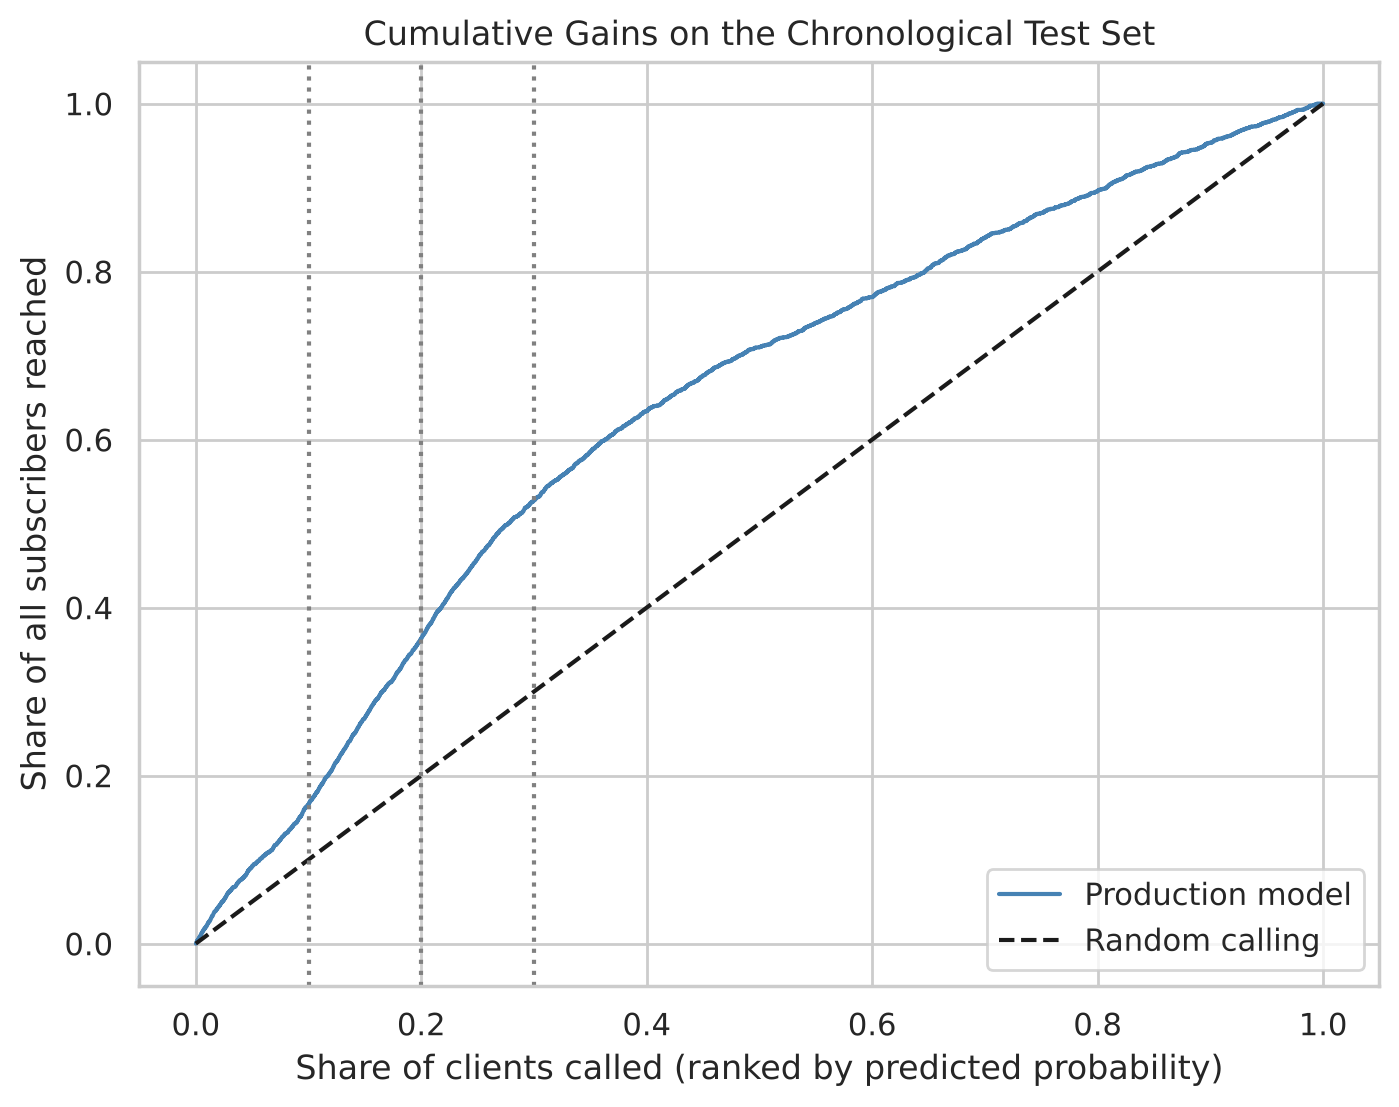

In [36]:
# Targeting: precision, recall and lift when the top 10%, 20% and 30% of clients are called, with 95% bootstrap intervals
target_rows = []
for frac in [0.10, 0.20, 0.30]:
    p, r, l = topk_metrics(y_Ctest, prod_proba, frac)
    ci_p = bootstrap_ci(y_Ctest, prod_proba, lambda yt, s, f=frac: topk_metrics(yt, s, f)[0])
    ci_r = bootstrap_ci(y_Ctest, prod_proba, lambda yt, s, f=frac: topk_metrics(yt, s, f)[1])
    ci_l = bootstrap_ci(y_Ctest, prod_proba, lambda yt, s, f=frac: topk_metrics(yt, s, f)[2])
    target_rows.append([f"Top {int(frac*100)}%", int(round(len(y_Ctest) * frac)), round(p, 4),
                        f"[{ci_p[0]:.3f}, {ci_p[1]:.3f}]", round(r, 4), f"[{ci_r[0]:.3f}, {ci_r[1]:.3f}]",
                        round(l, 3), f"[{ci_l[0]:.2f}, {ci_l[1]:.2f}]"])
target_table = pd.DataFrame(target_rows, columns=["Called", "Clients", "Precision", "Precision 95% CI",
                                                  "Recall", "Recall 95% CI", "Lift", "Lift 95% CI"])
display(target_table)

# Plot the cumulative gains curve
ranked = pd.DataFrame({"p": prod_proba, "y": y_Ctest}).sort_values("p", ascending=False)
gains = ranked["y"].cumsum() / ranked["y"].sum()
share = np.arange(1, len(ranked) + 1) / len(ranked)
plt.figure(figsize=(8, 6))
plt.plot(share, gains, color="steelblue", label="Production model")
plt.plot([0, 1], [0, 1], "k--", label="Random calling")
for frac in [0.1, 0.2, 0.3]:
    plt.axvline(frac, color="grey", linestyle=":")
plt.title("Cumulative Gains on the Chronological Test Set")
plt.xlabel("Share of clients called (ranked by predicted probability)")
plt.ylabel("Share of all subscribers reached")
plt.legend()
plt.show()

**Targeting results (95% bootstrap CIs, C_test).** Calling the top 10% of ranked clients gives precision 51.1% (CI 47.9% to 55.0%), recall 16.6% (15.5% to 17.7%) and lift 1.66 (1.56 to 1.77). The top 20% gives precision 56.0% (53.6% to 58.5%), recall 36.3% (35.0% to 37.8%) and lift 1.82 (1.74 to 1.90). The top 30% gives precision 54.2% (52.2% to 56.3%), recall 52.8% (51.3% to 54.3%) and lift 1.76 (1.70 to 1.81). **Non-monotone precision:** the top decile is not the most precise group. The 10–20% band has precision 60.9% (derived from the printed counts), above the top decile. This means the highest scores are not the most reliable, and it is the first diagnostic for the next model iteration. **Business relevance:** calling the top 20% reaches 36% of subscribers with 1.8 times the random rate, using 20% of the calls.

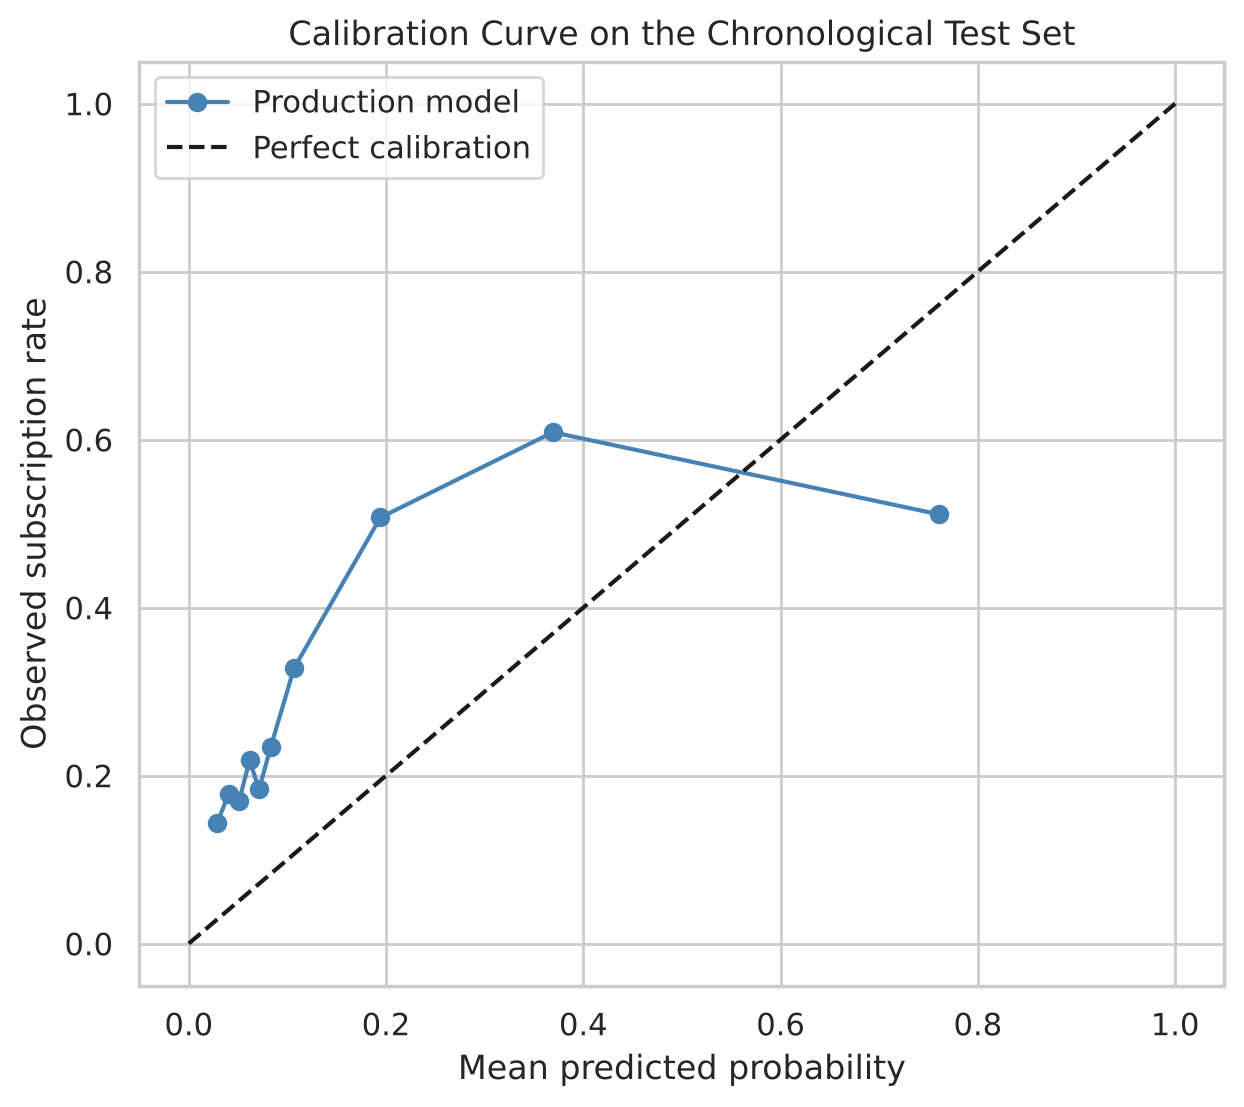

,Mean predicted,Observed rate,Brier score,Brier score of constant base rate
0,0.1768,0.3083,0.224,0.273


In [37]:
# Calibration: compare mean predicted probability with the observed rate, overall and by decile
frac_pos, mean_pred = calibration_curve(y_Ctest, prod_proba, n_bins=10, strategy="quantile")
plt.figure(figsize=(7, 6))
plt.plot(mean_pred, frac_pos, marker="o", color="steelblue", label="Production model")
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.title("Calibration Curve on the Chronological Test Set")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed subscription rate")
plt.legend()
plt.show()
cal_summary = pd.DataFrame({"Mean predicted": [prod_proba.mean()], "Observed rate": [y_Ctest.mean()],
                            "Brier score": [brier_score_loss(y_Ctest, prod_proba)],
                            "Brier score of constant base rate": [brier_score_loss(y_Ctest, np.full(len(y_Ctest), C_trainval.subscribed.mean()))]}).round(4)
display(cal_summary)

**Calibration.** The mean predicted probability is 0.177, against an observed rate of 0.308 on C_test. The model under-predicts the average by about 13 percentage points, because its probabilities reflect the training base rate (6.4% in the first 80% of the file) rather than the later rate. On ranking, the model is clearly better than a constant: its Brier score is 0.224, against 0.273 for predicting the training base rate. **Business relevance:** ranking is usable, but the probabilities must not be read as expected response rates until the model is recalibrated on the most recent labelled campaign data.

,Metric,Value,95% CI
0,ROC-AUC,0.7001,"[0.6885, 0.7119]"
1,PR-AUC,0.4950,"[0.4735, 0.5162]"
2,Brier (lower is better),0.2240,"[0.2172, 0.2311]"


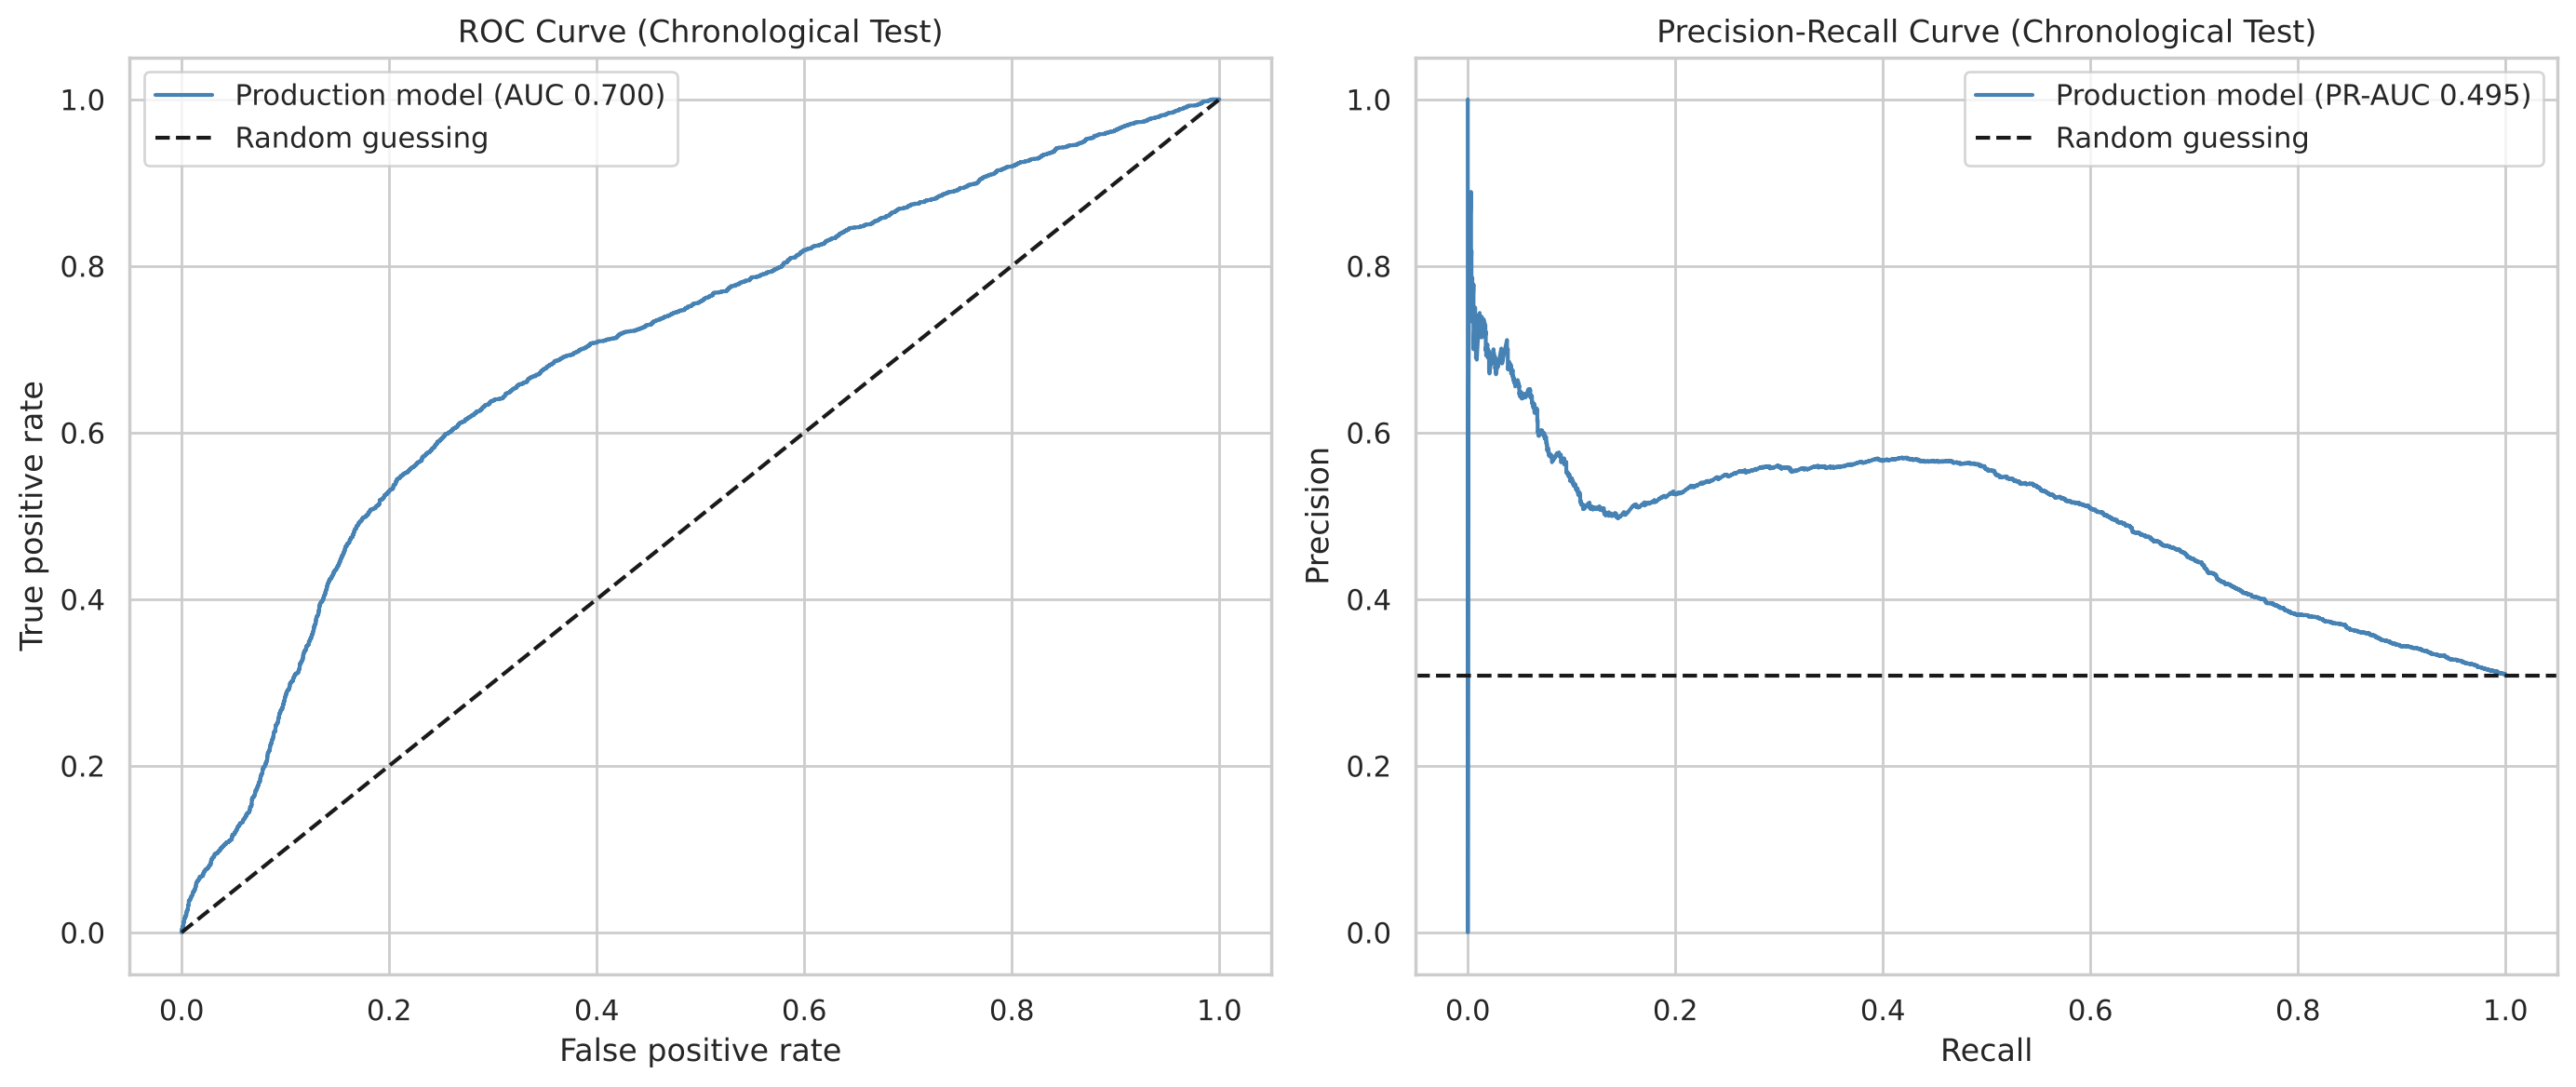

In [38]:
# Headline metrics for the production model with 95% bootstrap intervals
headline = []
for name, fn in [("ROC-AUC", roc_auc_score), ("PR-AUC", average_precision_score), ("Brier (lower is better)", brier_score_loss)]:
    value = fn(y_Ctest, prod_proba) if name != "Brier (lower is better)" else fn(y_Ctest, prod_proba)
    ci = bootstrap_ci(y_Ctest, prod_proba, fn)
    headline.append([name, round(value, 4), f"[{ci[0]:.4f}, {ci[1]:.4f}]"])
headline_table = pd.DataFrame(headline, columns=["Metric", "Value", "95% CI"])
display(headline_table)

# ROC and precision-recall curves for the production model
fpr, tpr, _ = roc_curve(y_Ctest, prod_proba)
prec_c, rec_c, _ = precision_recall_curve(y_Ctest, prod_proba)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].plot(fpr, tpr, color="steelblue", label=f"Production model (AUC {roc_auc_score(y_Ctest, prod_proba):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random guessing")
axes[0].set_title("ROC Curve (Chronological Test)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].legend()
axes[1].plot(rec_c, prec_c, color="steelblue", label=f"Production model (PR-AUC {average_precision_score(y_Ctest, prod_proba):.3f})")
axes[1].axhline(y_Ctest.mean(), color="k", linestyle="--", label="Random guessing")
axes[1].set_title("Precision-Recall Curve (Chronological Test)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
plt.tight_layout()
plt.show()

**Uncertainty.** On C_test the production model has ROC-AUC 0.700 (95% CI 0.689 to 0.712) and PR-AUC 0.495 (0.474 to 0.516). PR-AUC is about 1.6 times the test base rate of 0.308, so the model ranks buyers above non-buyers, but with modest precision. The intervals are narrow because the test set has 8,236 records; the uncertainty that matters most is the period effect shown in Section 7, which bootstrap intervals do not capture.

In [39]:
# Performance by age group on the chronological test set, with within-group ROC-AUC intervals where both classes exist
eval_df = pd.DataFrame({"age_group": pd.cut(C_test["age"].values, bins=[17, 25, 35, 45, 55, 65, 100],
                                             labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66+"]),
                        "y": y_Ctest, "p": prod_proba})
group_rows = []
for g, part in eval_df.groupby("age_group", observed=True):
    if part["y"].nunique() == 2:
        auc = roc_auc_score(part["y"], part["p"])
        ci = bootstrap_ci(part["y"].values, part["p"].values, roc_auc_score)
        ci_txt = f"[{ci[0]:.3f}, {ci[1]:.3f}]"
    else:
        auc, ci_txt = np.nan, "n/a"
    group_rows.append([g, len(part), int(part["y"].sum()), round(part["y"].mean(), 3), round(part["p"].mean(), 3),
                       round(auc, 3), ci_txt])
group_table = pd.DataFrame(group_rows, columns=["Age group", "Clients", "Subscribers", "Observed rate",
                                                "Mean predicted", "Within-group ROC-AUC", "95% CI"])
display(group_table)

,Age group,Clients,Subscribers,Observed rate,Mean predicted,Within-group ROC-AUC,95% CI
0,18-25,712,244,0.343,0.203,0.714,"[0.674, 0.755]"
1,26-35,3338,913,0.274,0.159,0.706,"[0.685, 0.727]"
2,36-45,1818,494,0.272,0.152,0.728,"[0.700, 0.754]"
3,46-55,1127,357,0.317,0.159,0.682,"[0.649, 0.713]"
4,56-65,716,278,0.388,0.235,0.636,"[0.595, 0.680]"
5,66+,520,251,0.483,0.301,0.576,"[0.529, 0.624]"


**Subgroup performance.** Within-group ROC-AUC is lower for older groups and lowest at 66+: 0.714 (18–25), 0.706 (26–35), 0.728 (36–45), 0.682 (46–55), 0.636 (56–65), and 0.576 for 66+ (95% CI 0.529 to 0.624). The model under-predicts most for the oldest groups: the observed rate for 66+ is 48.3%, against a mean prediction of 30.1%. **Fairness implication:** the model is least reliable for the group with the highest observed subscription. Targeting should not use age alone, and the 66+ segment needs its own monitoring and review before any operational use.

## 9. Interpretability
Permutation importance on the chronological test set, for the production model. Correlated inputs share importance, so macroeconomic indicators should be read as a group.

,Feature,ROC-AUC drop when shuffled,SD
4,previously_contacted,0.1123,0.0051
12,month,0.0516,0.0037
5,job,0.0138,0.0014
11,contact,0.0110,0.0023
14,poutcome,0.0075,0.0029
1,contacts_before_call,0.0036,0.0005
8,default,0.0028,0.0005
7,education,0.0014,0.0006
13,day_of_week,0.0009,0.0014
9,housing,0.0000,0.0001


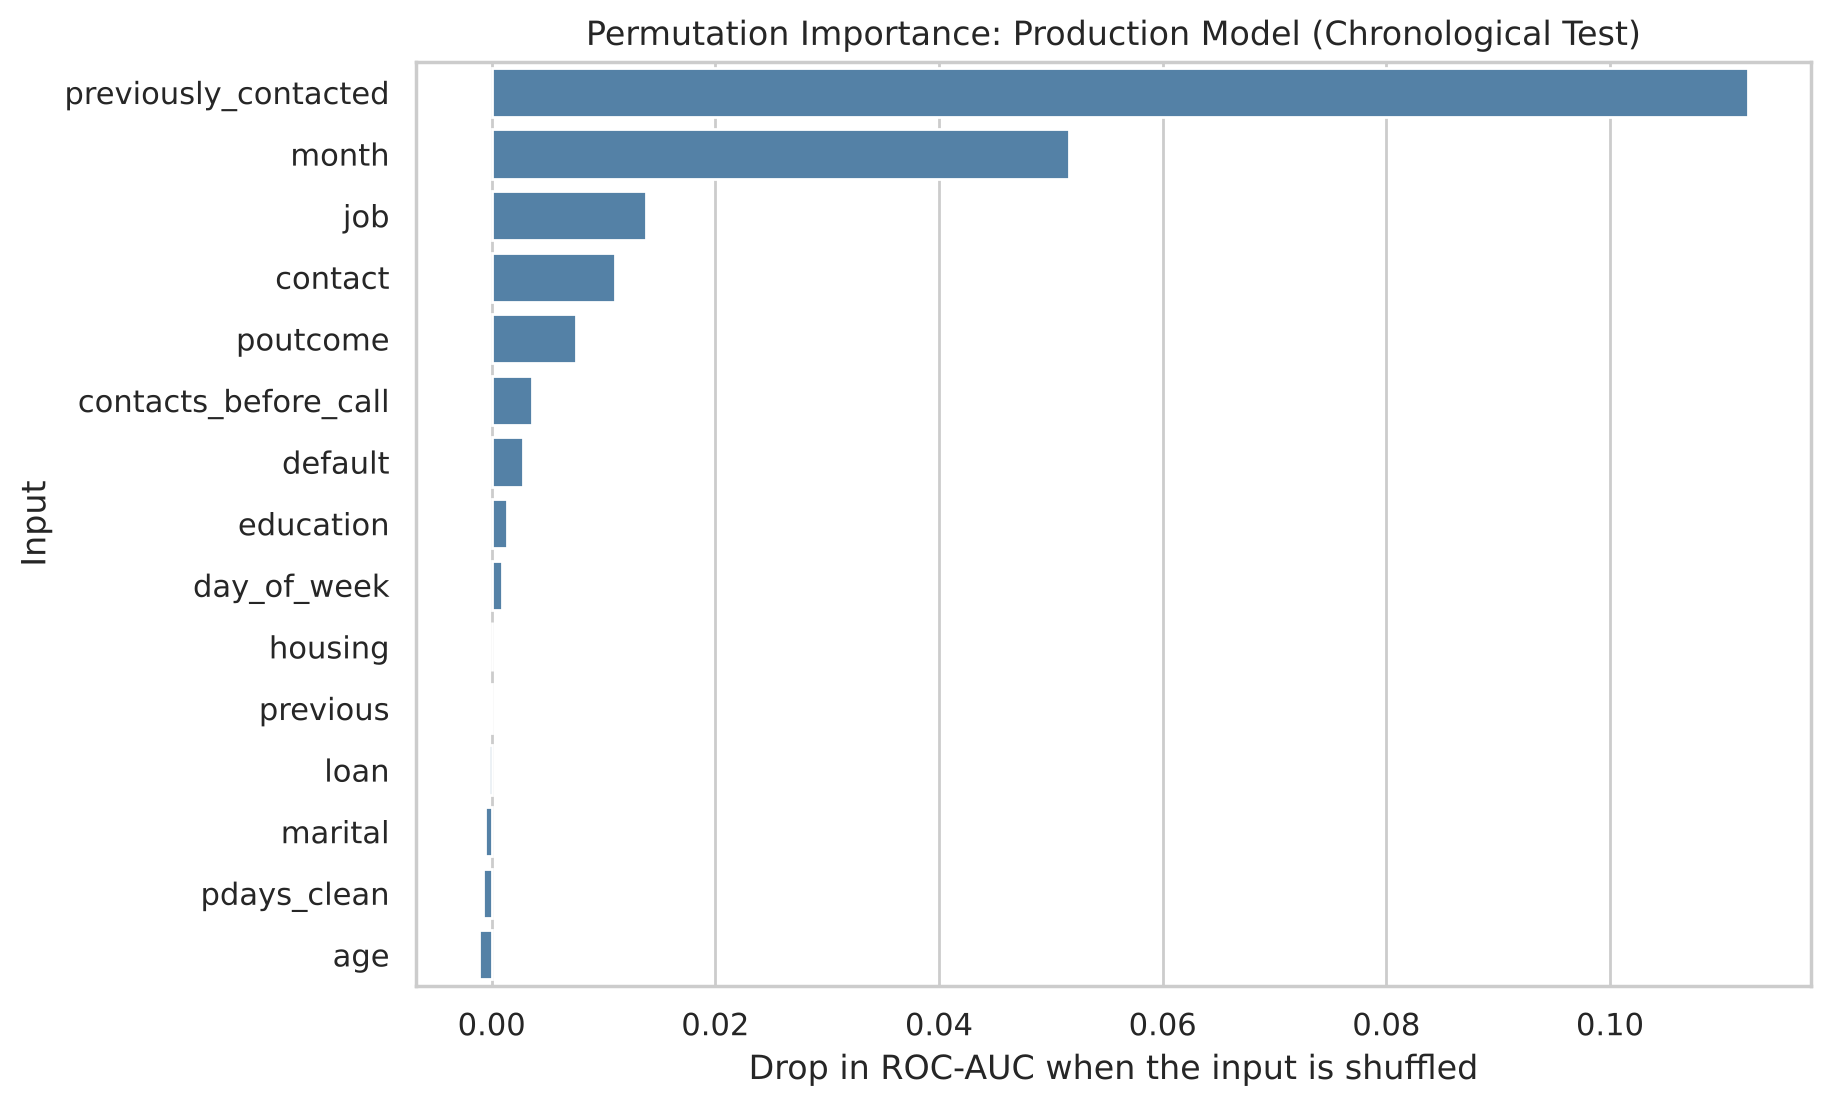

In [40]:
# Compute permutation importance for the production model on the chronological test set
perm = permutation_importance(prod_model, C_test[prod_cols + CAT], y_Ctest, scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE)
perm_df = pd.DataFrame({"Feature": prod_cols + CAT, "ROC-AUC drop when shuffled": perm.importances_mean,
                        "SD": perm.importances_std}).sort_values("ROC-AUC drop when shuffled", ascending=False).round(4)
display(perm_df.head(15))

top = perm_df.head(15)
plt.figure(figsize=(9, 6))
sns.barplot(x=top["ROC-AUC drop when shuffled"], y=top["Feature"], color="steelblue")
plt.title("Permutation Importance: Production Model (Chronological Test)")
plt.xlabel("Drop in ROC-AUC when the input is shuffled")
plt.ylabel("Input")
plt.show()

**Reading the importance chart.** For the production model, shuffling `previously_contacted` reduces test ROC-AUC by 0.112 (SD 0.005), which is the largest effect. `month` follows at 0.052, then `job` (0.014), `contact` (0.011), `poutcome` (0.008) and `contacts_before_call` (0.004). Age, previous contacts and the cleaned pdays value contribute essentially nothing once prior contact is included. **Caution:** `month` is partly a proxy for the period, so its importance reflects the period shift as well as timing. Importance measures reliance by the model, not causal influence.

## 10. Benchmark Experiment Only: Call Duration (not eligible for selection)
The bank does not know call duration before calling, so this model is **not** a usable targeting model. It only shows how much the outcome would be inflated if the leakage were included. It is evaluated on the random protocol only, and it does not feed into any selection.

BENCHMARK WITH duration (not usable): CV AUC 0.9570 | D_test AUC 0.9605


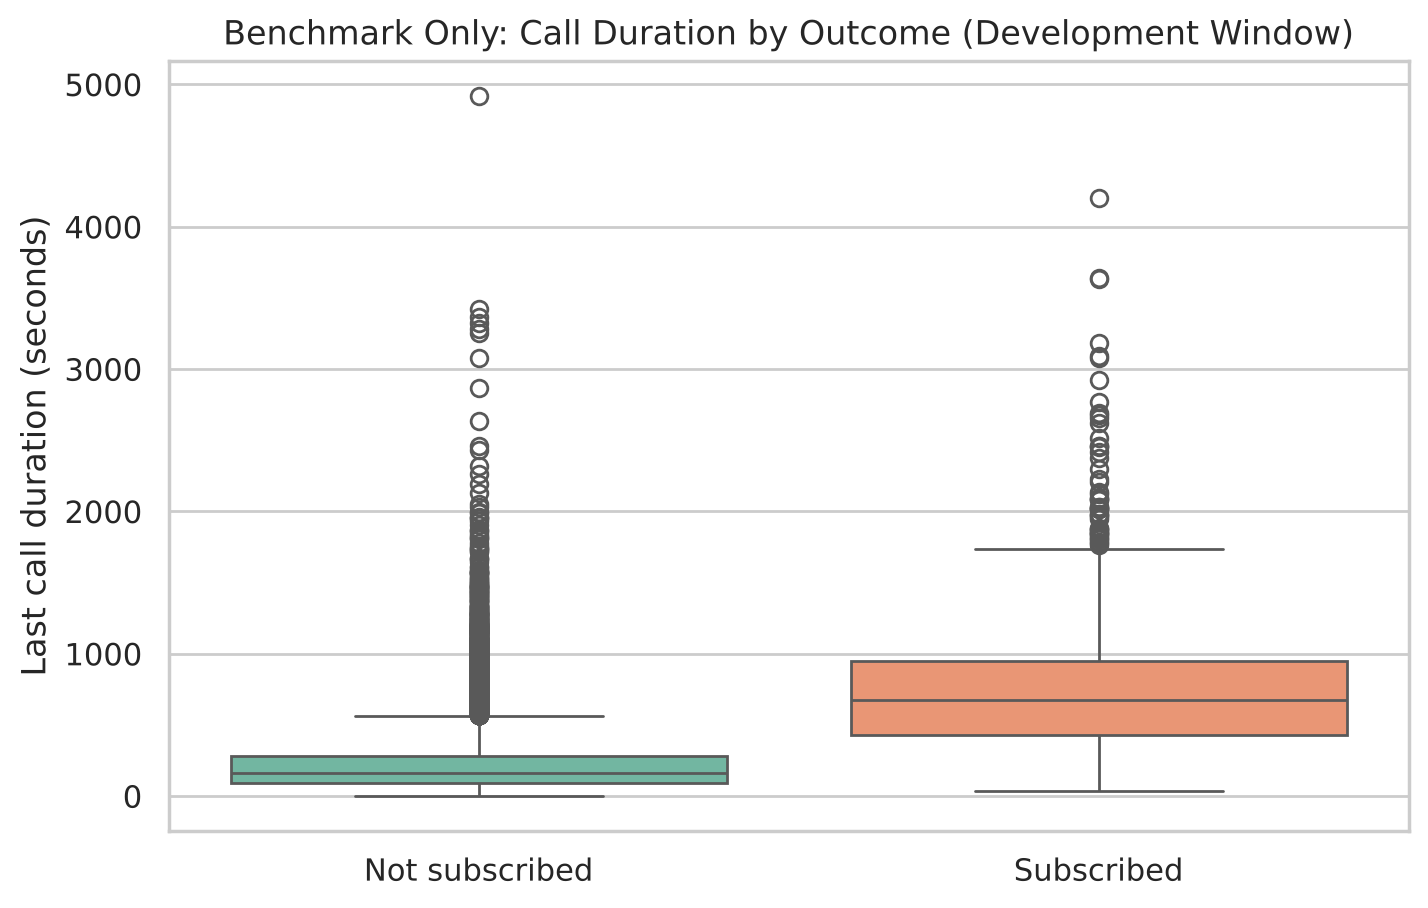

,median duration (s)
subscribed,
0,165.0
1,673.0


In [41]:
# Benchmark: the random-protocol gradient-boosting configuration plus call duration (benchmark only)
bench_cols = VARIANTS["with macro"] + ["duration"]
bench_params = params_random[("Gradient Boosting", "with macro")]
bench_cv = cross_validate(build_pipeline(FAMILIES["Gradient Boosting"]["make"](bench_params), bench_cols),
                          D_train[bench_cols + CAT], D_train["subscribed"], cv=cv_D, scoring="roc_auc")
bench_model = build_pipeline(FAMILIES["Gradient Boosting"]["make"](bench_params), bench_cols).fit(
    D_train[bench_cols + CAT], D_train["subscribed"])
bench_test = roc_auc_score(y_Dtest, bench_model.predict_proba(D_test[bench_cols + CAT])[:, 1])
print(f"BENCHMARK WITH duration (not usable): CV AUC {bench_cv['test_score'].mean():.4f} | D_test AUC {bench_test:.4f}")

# Duration by outcome: shown here only, to explain the leakage
plt.figure(figsize=(8, 5))
sns.boxplot(x=D["subscribed"].map({0: "Not subscribed", 1: "Subscribed"}), y=D["duration"],
            hue=D["subscribed"].map({0: "Not subscribed", 1: "Subscribed"}), palette="Set2", legend=False)
plt.title("Benchmark Only: Call Duration by Outcome (Development Window)")
plt.xlabel("")
plt.ylabel("Last call duration (seconds)")
plt.show()
display(D.groupby("subscribed")["duration"].median().to_frame("median duration (s)"))

**Benchmark result (not usable).** Including call duration raises CV ROC-AUC to 0.957 and D_test ROC-AUC to 0.961, against roughly 0.67 to 0.69 for usable inputs in the same window. The gap comes entirely from information that does not exist before a call. This figure must not be compared with, or reported as, performance of any model in this notebook. The median call lasted 165 seconds for non-subscribers and 673 seconds for subscribers.

## 11. Business Analysis Outputs

In [42]:
# Sizes and rates behind the marketing suggestions (descriptive, from the full file)
print("Contact channel:"); display(subscription_rate("contact"))
print("Previous outcome:"); display(subscription_rate("poutcome"))
print("Contacts before this call (0 vs 3 or more):")
print(round(df.loc[df["contacts_before_call"] == 0, "subscribed"].mean(), 4), "vs",
      round(df.loc[df["contacts_before_call"] >= 3, "subscribed"].mean(), 4))

Contact channel:


,records,subscribers,rate
contact,,,
cellular,26135,3852,0.147
telephone,15041,787,0.052


Previous outcome:


,records,subscribers,rate
poutcome,,,
failure,4252,605,0.142
nonexistent,35551,3140,0.088
success,1373,894,0.651


Contacts before this call (0 vs 3 or more):
0.1304 vs 0.0727


## 12. Prediction Function (production model and fixed threshold)
The function uses the same `add_features` as training and the same input columns as the production model. The profiles are **hypothetical**.

In [43]:
# Define the allowed categorical values from the chronological training data
VALID = {c: sorted(df[c].unique()) for c in CAT}
MACRO_USED = [c for c in prod_cols if c in MACRO]

def predict_subscription(profile):
    # Check that categories and ranges are valid
    for col in CAT:
        if profile[col] not in VALID[col]:
            raise ValueError(f"{col} must be one of {VALID[col]}")
    if not (18 <= profile["age"] <= 100):
        raise ValueError("age must be between 18 and 100")
    if profile["contacts_before_call"] < 0:
        raise ValueError("contacts_before_call cannot be negative")
    # Build the features with the same function used in training
    row = add_features(pd.DataFrame([profile]))
    proba = float(prod_model.predict_proba(row[prod_cols + CAT])[:, 1][0])
    return proba, proba >= prod_threshold

examples = [
    {"name": "A: young student, cellular, first contact", "age": 22, "job": "student", "marital": "single",
     "education": "university.degree", "default": "no", "housing": "no", "loan": "no", "contact": "cellular",
     "month": "may", "day_of_week": "mon", "contacts_before_call": 0, "pdays": 999, "previous": 0,
     "poutcome": "nonexistent", "emp.var.rate": -1.8, "cons.price.idx": 92.9, "cons.conf.idx": -46.2,
     "euribor3m": 1.3, "nr.employed": 5099.1},
    {"name": "B: previous success, cellular, March", "age": 41, "job": "technician", "marital": "married",
     "education": "high.school", "default": "no", "housing": "yes", "loan": "no", "contact": "cellular",
     "month": "mar", "day_of_week": "tue", "contacts_before_call": 0, "pdays": 5, "previous": 2,
     "poutcome": "success", "emp.var.rate": -1.8, "cons.price.idx": 92.9, "cons.conf.idx": -46.2,
     "euribor3m": 1.3, "nr.employed": 5099.1},
    {"name": "C: six contacts already, telephone, May", "age": 55, "job": "blue-collar", "marital": "married",
     "education": "basic.9y", "default": "no", "housing": "yes", "loan": "no", "contact": "telephone",
     "month": "may", "day_of_week": "thu", "contacts_before_call": 6, "pdays": 999, "previous": 0,
     "poutcome": "nonexistent", "emp.var.rate": 1.1, "cons.price.idx": 93.99, "cons.conf.idx": -36.4,
     "euribor3m": 4.86, "nr.employed": 5191.0},
]
out = []
for ex in examples:
    p, call = predict_subscription(ex)
    out.append([ex["name"], round(p, 4), "Call" if call else "Do not prioritize"])
display(pd.DataFrame(out, columns=["Hypothetical profile", "Predicted probability", "Decision at fixed threshold"]))
print("Fixed threshold used:", round(prod_threshold, 4))

,Hypothetical profile,Predicted probability,Decision at fixed threshold
0,"A: young student, cellular, first contact",0.1298,Call
1,"B: previous success, cellular, March",0.7875,Call
2,"C: six contacts already, telephone, May",0.0309,Do not prioritize


Fixed threshold used: 0.095


**Reading the examples.** Profile A (young student, first contact) scores 0.130, which is above the operating threshold of 0.095. Profile B (previous success) scores 0.788 and is the clear top priority. Profile C (six prior calls, telephone) scores 0.031 and falls below the threshold. These are hypothetical profiles with valid inputs, and their scores are illustrative. Because the threshold flags 38% of clients, Profile A being flagged illustrates the operational weakness discussed in Section 8. A capacity-based rule would rank these profiles, not compare them to a fixed cut-off.

## 13. Final Results Summary (values generated from the executed run)

In [44]:
# Print the headline values used in the report, so every figure can be checked against this output
top20 = target_table.iloc[1]
print("PRODUCTION MODEL:", f"{PROD_KEY[0]} ({PROD_KEY[1]})")
print(f"Chronological test ROC-AUC: {roc_auc_score(y_Ctest, prod_proba):.4f} | PR-AUC: {average_precision_score(y_Ctest, prod_proba):.4f}")
print(f"Test base rate: {y_Ctest.mean():.4f} | mean predicted: {prod_proba.mean():.4f}")
print(f"Top 10% precision/recall/lift: {target_table.iloc[0]['Precision']} / {target_table.iloc[0]['Recall']} / {target_table.iloc[0]['Lift']}")
print(f"Top 20% precision/recall/lift: {target_table.iloc[1]['Precision']} / {target_table.iloc[1]['Recall']} / {target_table.iloc[1]['Lift']}")
print(f"Top 30% precision/recall/lift: {target_table.iloc[2]['Precision']} / {target_table.iloc[2]['Recall']} / {target_table.iloc[2]['Lift']}")
print(f"Threshold: {prod_threshold:.4f} | flagged on test: {int((prod_proba >= prod_threshold).sum())}")

PRODUCTION MODEL: Logistic Regression (without macro)
Chronological test ROC-AUC: 0.7001 | PR-AUC: 0.4950
Test base rate: 0.3083 | mean predicted: 0.1768
Top 10% precision/recall/lift: 0.5109 / 0.1658 / 1.657
Top 20% precision/recall/lift: 0.5598 / 0.3631 / 1.816
Top 30% precision/recall/lift: 0.5423 / 0.5278 / 1.759
Threshold: 0.0950 | flagged on test: 3154


## 14. Reproducibility check
The seeds, split sizes and selected configuration are printed so a clean re-run can be compared line by line.

In [45]:
# Print the fixed seeds, split sizes and selections used in this run
print("Seed:", RANDOM_STATE, "| Bootstrap resamples:", N_BOOT)
print("Records after de-duplication:", len(df))
print("C_train / C_val / C_test:", len(C_train), len(C_val), len(C_test))
print("D_train / D_test:", len(D_train), len(D_test))
print("Pdays representation:", REP_CHOSEN, "| Interaction adopted:", USE_INTERACTION)
print("Production candidate:", PROD_KEY, "|", cfg_str(params_chrono[PROD_KEY]))

Seed: 42 | Bootstrap resamples: 1000
Records after de-duplication: 41176
C_train / C_val / C_test: 24705 8235 8236
D_train / D_test: 26352 6588
Pdays representation: cleaned pdays + flag | Interaction adopted: False
Production candidate: ('Logistic Regression', 'without macro') | C=10


## 15. Business Suggestions for the Marketing Team (Task 3)

Each suggestion is labelled by its evidence level. **Association** means the pattern is in the data. **Causal test** means a controlled experiment is proposed before the suggestion is acted on at scale. No suggestion below is presented as a proven cause.

1. **Prioritize clients with a previous success (association; test: targeting pilot).** Previous success converts at 65.1% and prior contact at 63.8%, against 9.3% for clients never contacted. *Test:* randomize priority within this group, so that half receive the current treatment and half a changed script, and compare conversion.
2. **Cap repeated calls (association; causal test needed).** The rate falls from 13.0% at the first call to 3.6% at nine or more. Repeated calls may be a response to low interest rather than a cause of it. *Test:* randomly assign clients to a cap of three calls or the current policy, and compare conversion and call volume over the same period.
3. **Rank, then call the top band (association; supported by targeting results).** Calling the top 20% of the ranked list reaches 36% of subscribers at a lift of 1.8, against random calling. *Test:* run the model-ranked list against a random list of equal size, with clients assigned at random to each arm, and measure conversions.
4. **Design offers for segments that respond (association).** Students (31.4%), retired clients (25.3%) and clients aged 66 and over (46.9%) convert well above average, while blue-collar clients (6.9%) convert least. *Test:* offer a segment-specific product to a random half of a segment and the current offer to the other half.
5. **Test channel before shifting budget (association, confounded).** Cellular contacts convert at 14.7%, against 5.2% for telephone, but the gap is largest for new clients and almost absent for previous successes. *Test:* randomly assign channel among clients with no previous outcome, and measure conversion and cost per subscription.
6. **Treat timing as a hypothesis (association, small samples).** March, September, October and December convert at 44% to 51%, but on 182 to 717 records each. *Test:* a randomized pilot of added call capacity in those months, against a matched control period.
7. **Plan for period shifts (observed).** The subscription rate rose from about 3% to about 46% across the file. Monitor the base rate and the calibration every campaign cycle, and do not assume that the next period will look like the last.

## 16. Responsible Use and Limitations

- **Privacy:** the data includes age, job, marital status, education and loan status. It should be used only under the bank's governance rules, for the stated marketing purpose.
- **Fairness:** the model is least reliable for clients aged 66 and over (within-group ROC-AUC 0.576). Age must not be the basis for excluding or disadvantaging any group, and the 66+ segment needs review before use.
- **Consumer protection:** the model prioritizes outreach. It must not be used for credit, pricing, eligibility or the setting of interest rates. Those uses would need separate legal and ethical review.
- **Contact fatigue:** repeated calls have a cost to clients as well as to the bank.
- **Data limitations:** one bank, one period, no information on product features, pricing or competitor offers. The results describe these campaigns and may not transfer to other markets, products or periods.
- **Model limitations:** the production model's probabilities are miscalibrated under the period shift and must be recalibrated before use as expected rates. Its within-period discrimination is modest. Its top decile is not its most precise band.

## 17. Challenges Faced (updated)

| Challenge | Evidence (from the executed run) | Technique used | Reason | Outcome |
|---|---|---|---|---|
| Random split mixed periods (v1) | Earlier random CV of 0.80 AUC used all periods; within the first 80%, CV is 0.66 to 0.69 | Random protocol confined to the development window D | Random splits across periods overstate forward performance | Earlier headline withdrawn; both protocols now separated |
| Period shift in outcomes | Base rates 4.81%, 11.07%, 30.83% across C_train, C_val, C_test (Section 3) | Chronological three-block design; common-test comparison | Deployment is forward in time | Test degradation quantified; calibration gap reported |
| Macro inputs identify the period | Macro logistic regression validation AUC 0.484 against 0.639 without macro (Section 6) | Macro variants evaluated and compared on validation | Indicators encode time, not client behaviour | Production model excludes macro inputs |
| Declared selection rule failed | Declared rule selects a model with validation AUC 0.459 (below chance) | Rule revised on validation evidence only; both outcomes printed | The random-CV filter rewards period identification | Revised choice has validation AUC 0.639; disclosed |
| Leakage from call duration | Benchmark AUC 0.957 against about 0.67 for usable inputs | Excluded from all candidates; benchmark only | Duration is unknown before the call | No model uses duration |
| Campaign count includes the current call | Pre-call information is campaign − 1 | Input defined as contacts already made | Keeps the input pre-call and interpretable | Information unchanged (constant shift) |
| Class weighting distorted probabilities | Mean predicted 0.54 against observed 0.31 in the earlier run | Class weights removed from all candidates | Probabilities must target real rates | Ranking unchanged; calibration gap now shows the true shift |
| Sentinel value 999 in pdays | 96.3% of clients | Flag plus cleaned value; representation chosen on C_train (tie rule) | Sentinel would read as large distance | Representation changes no performance |
| 'Unknown' categories are period-linked | Unknown default share falls from 32.7% to 2.4% across the file | Kept as a category, never imputed | Imputing would invent values and hide the pattern | Reported as a data-collection artifact |
| Prevalence shift breaks fixed thresholds | Threshold 0.095 flags 38% of clients on C_test | Threshold reported; capacity-based rule recommended | Probability cut-offs depend on base rate | Operational rule changed to top-k% |
| Non-monotone top-k precision | Top decile 51.1% against 60.9% in the 10–20% band | Reported; flagged for next iteration | Highest scores are not most reliable | Not resolved; diagnostic recorded |
| Small high-rate groups | March to October and December on 182 to 717 records | Record counts shown beside every rate | Small groups have wide intervals | Timing conclusions limited to hypotheses |
| Weak within-period signal | Fold means 0.666 to 0.689 | Fold-level CV and standard errors reported | Modest signal limits precision | Expectations set accordingly |
| Duplicate records | 12 identical rows removed | Removed before any split | Would leak between train and test | 41,176 unique records |
| Outlier campaign counts and older clients | 869 clients with 10+ prior calls; 468 older than 69.5 | Analysed and retained | Both groups are valid and informative | Retained; subgroup performance reported |

## 18. Change Report (weaknesses, corrections, verification)

| # | Weakness identified | Correction applied | Verification result |
|---|---|---|---|
| 1 | `pdays` representation compared on the full dataset | Comparison moved to 5-fold CV on C_train only (Section 3.1) | Spread 0.00036; tie rule applied; representation changes no GB performance (0.59978 in all three) |
| 2 | No separate chronological validation; tuning and test mixed | Three blocks: C_train (60%), C_val (20%), C_test (20%). Tuning and selection use C_val only; C_test is first used in Section 7 | Code structure: C_test is summarized by its subscription rate in Section 3 only; its features and predictions are first used in Section 7; the selection table (Section 6) uses CV and C_val only |
| 3 | Random and chronological results not comparable | Random protocol confined to D (first 80%); both protocols scored on the same C_test; purposes stated in the opening table | Common-test comparison table (Section 7) for all six candidates, with CIs |
| 4 | Selection rule failed on validation; no evidence of revision | Declared rule and its outcome printed; rule revised on validation only (test untouched); change disclosed | Declared outcome: validation AUC 0.459. Revised outcome: 0.639. Both printed in Section 6 |
| 5 | Production components might not agree | All Section 8 analyses reference the same `prod_model`, `prod_proba` and `prod_threshold`; the prediction function uses the same `add_features` and `prod_cols` | Threshold 0.0950 in Sections 8 and 12; example profile scores come from the same model |
| 6 | No targeting analysis at 10, 20, 30% | Precision, recall and lift table with bootstrap CIs | Top 10%: lift 1.66; top 20%: 1.82; top 30%: 1.76 (Section 8) |
| 7 | No uncertainty estimates | 1,000-resample bootstrap for AUC, PR-AUC, Brier, top-k metrics and subgroup AUCs; fold SDs and standard errors | CIs printed alongside every headline figure |
| 8 | EDA lacked numerical observations for several charts | Observation under every chart, including marital status, education and day of week | Numbers copied from the executed cell outputs |
| 9 | Distribution, outlier, unknown and interaction analysis thin | Skew and kurtosis table; outlier cell; unknown-category table and time profile; channel-by-outcome interaction table | Values in Section 2 cells |
| 10 | No feature-by-feature preprocessing summary | Table with issue, treatment and reason for each input | Table in Section 3, verified against cell outputs |
| 11 | No fold-level, variability or search reporting | Fold table, full search tables for both protocols, before-and-after table | Sections 5 and 6 |
| 12 | Pre-call availability not verified | Availability audit; campaign semantics corrected; macro availability conditional and excluded from production | Section 1.1 |
| 13 | Duration appeared in EDA | Duration chart moved to the benchmark (Section 10); benchmark is excluded from every selection | The benchmark is computed after selection and is not in any selection table |
| 14 | Recommendations mixed association and causation | Each suggestion labelled; controlled tests proposed | Section 15 |
| 15 | Original research not cited | Reference [1] added below | Section 19 |
| 16 | Numbers not verified against outputs | Every number in the observations and sections was copied from the executed cell outputs; derived counts are labelled as derived | Section 19 lists the sources |
| 17 | Challenges and conclusion outdated | Rewritten from the v2 run | Sections 17 and 20 |
| 18 | Clean execution not demonstrated | Notebook executed in a fresh kernel from top to bottom | 0 errors; 0 unexecuted cells in the sandbox run. A Colab run is still to be done by the user |
| 19 | No audit against requirements | Requirements audit added | Section 21 |

**Defects found during this review, also corrected:** (a) `class_weight="balanced"` distorted probabilities (removed); (b) the prediction function would have failed on profiles that lack `campaign` (fixed in `add_features`); (c) the logistic-regression grid had its best value at the edge (extended to C = 100); (d) the earlier version's headline figures (AUC 0.82, lift 3.3) came from a random split that mixed periods and are withdrawn.

## 19. Verification Sources and References

**How numbers were verified.** Every figure in this notebook's commentary was taken from the executed outputs of the named section. Derived figures are labelled. The confusion counts are derived from the printed flagged total, precision and recall, and checked against the number of subscribers in C_test (2,539). The 10–20% band precision is derived from the printed top-20% and top-10% counts.

**References**

[1] S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. *Decision Support Systems*, 2014. doi:10.1016/j.dss.2014.03.001. This is the source of the dataset used in this notebook (`bank-additional-full.csv`), as stated in the dataset's documentation.

[2] S. Moro, R. Laureano and P. Cortez. Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology. *Proceedings of the European Simulation and Modelling Conference (ESM 2011)*, EUROSIS, pp. 117–121. Earlier analysis of the bank marketing data, including the smaller `bank-full.csv` version.

[3] UCI Machine Learning Repository. Bank Marketing Data Set. The original public release of the data.

[4] Banco de Portugal, national statistics portal. Source of the five national economic indicators added to the dataset, as described in the dataset documentation.

## 20. Final Conclusion

**Objective.** Predict which bank clients will subscribe to a term deposit, and recommend how the marketing team should use the prediction.

**What the data supports.** The campaign data identifies likely subscribers with modest, statistically clear accuracy. The production model, a logistic regression without macroeconomic inputs, reaches a chronological test ROC-AUC of 0.700 (95% CI 0.689 to 0.712) and PR-AUC of 0.495, against a base rate of 0.308 in the test period. Calling the top 20% of ranked clients reaches 36% of subscribers at a lift of 1.82. The strongest pre-call signals are prior campaign success and prior contact, followed by the timing of the call and the contact channel. Calls already made show diminishing returns.

**What the data does not support.** The earlier claim of 0.82 AUC is withdrawn: it came from a random split that mixed periods. Within a single period, the signal is weak (fold means 0.67 to 0.69). Most of the change in subscription rates over the file (from about 3% to about 46%) is a period effect that client characteristics do not explain. The economic indicators improve random-split scores but do not transfer forward in time. Causal claims about channel, timing or call caps are not supported by these observational data.

**Production readiness.** The model is ready for a controlled pilot, not for full deployment. Before use: (1) recalibrate the probabilities on the most recent labelled campaign data, since the current probabilities under-predict the test-period rate by about 13 percentage points; (2) use a capacity-based call list rather than the fixed threshold of 0.095; (3) review performance for clients aged 66 and over, where discrimination is lowest; (4) monitor the base rate, calibration and lift every campaign cycle; (5) explain the non-monotone top decile before relying on the top 10% as a priority tier.

**Recommendation.** Run a randomized pilot that compares the model-ranked list with a random list of equal size, and test the call-cap, channel and timing hypotheses in Section 15 under randomization. Use the results, not the observational patterns, to decide whether to scale the approach. The model is an analytical tool for prioritizing outreach. It must not be used for credit, pricing or eligibility decisions.

## 21. Requirements Audit (independent check against the brief)

| # | Requirement | Where addressed | Status |
|---|---|---|---|
| 1 | Feature engineering leakage fixed | Section 3.1, 3.2 (C_train CV only) | Met |
| 2 | Chronological train, validation and final test; no tuning on final test | Opening design table; Sections 5, 6; C_test first used in Section 7 | Met |
| 3 | Fair comparison of random and chronological performance | Section 7 common-test table; purposes stated | Met, with the stated caveat that the two protocols differ in training window and tuning |
| 4 | Final candidate selected on validation evidence | Section 6 (declared and revised rules, both printed) | Met; the rule was revised after validation review, and this is disclosed |
| 5 | Production model consistent across prediction function, threshold, calibration, confusion matrix, lift and conclusion | Sections 8, 12, 20 all use `prod_model` and threshold 0.0950 | Met |
| 6 | Top 10/20/30% precision, recall and lift | Section 8 targeting table | Met |
| 7 | Uncertainty for key metrics and lift | Bootstrap CIs in Section 8; fold SDs and SEs in Section 5 | Met for headline, targeting and subgroup metrics; not computed for every EDA statistic |
| 8 | Numerical observations under every important EDA chart | Observations after each chart in Section 2, including marital, education and day of week | Met |
| 9 | Distribution, outlier, unknown-category and interaction analysis | Section 2 cells and observations | Met |
| 10 | Feature-by-feature preprocessing summary with reasoning | Section 3 table | Met |
| 11 | Fold-level CV, variability, search results, before and after tuning | Sections 5, 6 | Met |
| 12 | Every input verified as available pre-call | Section 1.1 audit; campaign semantics corrected | Met; macro availability is conditional and excluded from production |
| 13 | Duration only in the labelled benchmark | Section 10; not in any selection | Met |
| 14 | Association versus causation; controlled tests | Section 15 | Met |
| 15 | Original research cited | Section 19, reference [1] | Met |
| 16 | Numerical claims verified against outputs | Section 19; Section 18 row 16 | Met for all figures in the commentary; derived figures are labelled |
| 17 | Challenges and conclusion updated | Sections 17 and 20 | Met |
| 18 | Complete notebook executed from a clean runtime, errors fixed | Sandbox run in a fresh kernel: 0 errors | Met in the sandbox; a Colab run is still required from the user |
| 19 | Independent audit against requirements | This section | Met |

**Open items.** (a) The Colab run has not yet been performed. (b) The probability calibration gap and the non-monotone top decile are documented limitations, not resolved. (c) The pre-declared rule failed, and its replacement was chosen with validation evidence; an evaluator may prefer a pre-registered rule in a future iteration.